# Mount Drive, Unpack Cached Data & Load Baseline 2

This initializes the environment, rebuilds the 55-crop / 175-disease / 333-pair mappings from dpd_small_320.zip, and loads your Baseline 2 checkpoint into memory.

In [2]:
import os, sys, json, copy, shutil, subprocess
if 'google.colab' in sys.modules:
    from google.colab import drive
    try:
        drive.mount('/content/drive')
        os.listdir('/content/drive/MyDrive')
    except OSError:
        subprocess.run(['fusermount', '-u', '/content/drive'], check=False)
        drive.mount('/content/drive', force_remount=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm'], check=True)

import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import timm

def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEVICE == 'cuda'

CFG = dict(
    drive_root='/content/drive/MyDrive/COS30082',
    b2_ckpt='/content/drive/MyDrive/COS30082/outputs/baseline2_multitask_vit/final/best.pt',
    out_dir='/content/drive/MyDrive/COS30082/outputs/model5_factorized_vit',
    local_root='/content',
    cache_size=320,
    backbone='vit_base_patch16_224',
    img_size=224,
    batch_size=64,
    num_workers=2,
    # Model 5 hyperparameters
    s1_epochs=18,
    s1_lr_backbone=3e-5,
    s1_lr_head=3e-4,
    lambda_orth=0.5,
    supcon_temp=0.07,
    proj_dim=128,
    s2_epochs=12,
    s2_lr_head=1e-3,
    weight_decay=1e-4,
    init_from_b2=True,
)
os.makedirs(CFG['out_dir'], exist_ok=True)

# 1. Copy sequentially to local SSD before unpacking to prevent Drive FUSE disconnects
CACHE_DIR = os.path.join(CFG['local_root'], f"dpd_small_{CFG['cache_size']}")
CACHE_ZIP = os.path.join(CFG['drive_root'], 'cache', f"dpd_small_{CFG['cache_size']}.zip")
LOCAL_ZIP = os.path.join(CFG['local_root'], f"dpd_small_{CFG['cache_size']}.zip")
IMAGE_DIR = os.path.join(CACHE_DIR, 'DPD_Small_dataset')

if not os.path.exists(os.path.join(CACHE_DIR, '.complete')):
    if not os.path.exists(CACHE_ZIP):
        raise FileNotFoundError(f"Cached archive missing at {CACHE_ZIP}")
    if os.path.exists(CACHE_DIR):
        shutil.rmtree(CACHE_DIR, ignore_errors=True)
    print('Copying cached zip sequentially from Drive to local SSD...')
    shutil.copyfile(CACHE_ZIP, LOCAL_ZIP)
    print('Unpacking locally...')
    subprocess.run(['unzip', '-q', LOCAL_ZIP, '-d', CFG['local_root']], check=True)
    os.remove(LOCAL_ZIP)
    print('Dataset unpacked.')

COLS = ['file', 'crop', 'disease', 'comp', 'crop_name', 'disease_name', 'comp_name']
train_df = pd.read_csv(os.path.join(CACHE_DIR, 'DPD_Small_train.csv'), header=None, names=COLS)
test_seen_df = pd.read_csv(os.path.join(CACHE_DIR, 'DPD_Small_test_seen.csv'), header=None, names=COLS)
test_unseen_df = pd.read_csv(os.path.join(CACHE_DIR, 'DPD_Small_test_unseen.csv'), header=None, names=COLS)
all_df = pd.concat([train_df, test_seen_df, test_unseen_df], ignore_index=True)

comps = (all_df.drop_duplicates('comp').sort_values('comp')
         [['comp', 'crop', 'disease', 'crop_name', 'disease_name', 'comp_name']]
         .reset_index(drop=True))

NUM_CROPS = int(all_df['crop'].max()) + 1        # 55
NUM_DISEASES = int(all_df['disease'].max()) + 1  # 175
NUM_COMPS = len(comps)                           # 333

COMP_CROP = torch.tensor(comps['crop'].values)
COMP_DIS = torch.tensor(comps['disease'].values)
FIT_COMPS = sorted(set(train_df['comp']))
NOVEL_MASK = torch.ones(NUM_COMPS, dtype=torch.bool)
NOVEL_MASK[FIT_COMPS] = False

# 2. Load Baseline 2 ViT model
class MultiTaskViT(nn.Module):
    def __init__(self, backbone, n_crops, n_diseases, pretrained=False, dropout=0.2):
        super().__init__()
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0)
        d = self.backbone.num_features
        self.dropout = nn.Dropout(dropout)
        self.crop_head = nn.Linear(d, n_crops)
        self.disease_head = nn.Linear(d, n_diseases)

    def forward(self, x):
        feat = self.backbone(x)
        h = self.dropout(feat)
        return self.crop_head(h), self.disease_head(h), feat

b2_model = MultiTaskViT(CFG['backbone'], NUM_CROPS, NUM_DISEASES, pretrained=False).to(DEVICE)
b2_ckpt = torch.load(CFG['b2_ckpt'], map_location=DEVICE, weights_only=False)
b2_model.load_state_dict(b2_ckpt['model'])
b2_model.eval()

B2_BIAS = 4.995
for folder_name in ('basline2_multitask_vit', 'baseline2_multitask_vit'):
    p = os.path.join(CFG['drive_root'], 'outputs', folder_name, 'dev', 'summary.json')
    if os.path.exists(p):
        B2_BIAS = json.load(open(p))['best_bias']
        break

print(f"Device: {DEVICE} | Baseline 2 loaded (epoch {b2_ckpt.get('epoch', 'N/A')}, bias={B2_BIAS:.3f})")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | Baseline 2 loaded (epoch 17, bias=4.995)


# Data Loaders & Compositional Dev Split

Stage 1 requires two augmented views per image for Supervised Contrastive Learning (TwoCropTransform), while Stage 2 uses single-view augmentation for linear probing. This cell also constructs a compositional validation split (dev_fit, dev_seen, dev_unseen) from train_df so novelty bias $b$ is calibrated without touching test_unseen.

In [3]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(CFG['img_size'], scale=(0.7, 1.0), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_tf = transforms.Compose([
    transforms.Resize((CFG['img_size'], CFG['img_size']), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

class TwoViewTransform:
    def __init__(self, base_tf):
        self.base_tf = base_tf
    def __call__(self, img):
        return self.base_tf(img), self.base_tf(img)

class DPDSmallDataset(Dataset):
    def __init__(self, df, img_dir, transform):
        self.files = df['file'].tolist()
        self.labels = df[['crop', 'disease', 'comp']].to_numpy()
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img = Image.open(os.path.join(self.img_dir, self.files[i])).convert('RGB')
        crop, disease, comp = self.labels[i]
        return self.transform(img), int(crop), int(disease), int(comp)

def make_loader(df, transform, shuffle=False, drop_last=False):
    ds = DPDSmallDataset(df, IMAGE_DIR, transform)
    return DataLoader(
        ds, batch_size=CFG['batch_size'], shuffle=shuffle,
        num_workers=CFG['num_workers'], pin_memory=AMP, drop_last=drop_last
    )

def make_compositional_dev_split(df, unseen_comp_frac=0.15, seen_img_frac=0.15, seed=42):
    rng = np.random.default_rng(seed)
    comp_counts = df['comp'].value_counts()
    crop_comp_counts = df.drop_duplicates('comp')['crop'].value_counts().to_dict()
    dis_comp_counts = df.drop_duplicates('comp')['disease'].value_counts().to_dict()

    candidates = df.drop_duplicates('comp').sample(frac=1.0, random_state=seed)
    target_unseen = int(len(candidates) * unseen_comp_frac)
    dev_unseen_comps = []

    for _, row in candidates.iterrows():
        if len(dev_unseen_comps) >= target_unseen:
            break
        c, d, comp_id = int(row['crop']), int(row['disease']), int(row['comp'])
        # Ensure every primitive remains present in dev_fit
        if crop_comp_counts[c] > 1 and dis_comp_counts[d] > 1:
            dev_unseen_comps.append(comp_id)
            crop_comp_counts[c] -= 1
            dis_comp_counts[d] -= 1

    dev_unseen_set = set(dev_unseen_comps)
    dev_unseen_df = df[df['comp'].isin(dev_unseen_set)].reset_index(drop=True)
    rem_df = df[~df['comp'].isin(dev_unseen_set)].copy()

    # Hold out 15% of images from remaining seen pairs as dev_seen
    seen_val_idx = []
    for comp_id, grp in rem_df.groupby('comp'):
        if len(grp) >= 4:
            n_val = max(1, int(len(grp) * seen_img_frac))
            seen_val_idx.extend(rng.choice(grp.index.to_numpy(), size=n_val, replace=False))

    dev_seen_df = rem_df.loc[seen_val_idx].reset_index(drop=True)
    dev_fit_df = rem_df.drop(index=seen_val_idx).reset_index(drop=True)
    return dev_fit_df, dev_seen_df, dev_unseen_df

dev_fit_df, dev_seen_df, dev_unseen_df = make_compositional_dev_split(train_df)
print(f"Dev Split -> Fit: {len(dev_fit_df)} | Dev-Seen: {len(dev_seen_df)} | Dev-Unseen: {len(dev_unseen_df)}")

Dev Split -> Fit: 5324 | Dev-Seen: 847 | Dev-Unseen: 1829


# Model 5 Architecture & Factorized SupCon + Orthogonality Loss

Model 5 splits the 768-d ViT [CLS] representation into two 384-d subspaces:
* $z_{\text{crop}} = \text{feat}[:, :384]$
* $z_{\text{disease}} = \text{feat}[:, 384:]$

During Stage 1, separate non-linear projection heads map each 384-d subspace onto a 128-d hypersphere for Supervised Contrastive Loss ($\mathcal{L}_{\text{SupCon}}$), while a cosine orthogonality penalty ($\lambda_{\text{orth}} = 0.5$) forces $z_{\text{crop}} \perp z_{\text{disease}}$. During Stage 2, the ViT encoder is frozen and independent linear probes classify crop and disease directly from their respective 384-d subspaces.

In [4]:
class SupConLoss(nn.Module):
    """Supervised Contrastive Loss (Khosla et al., 2020) computed in FP32 for numerical stability."""
    def __init__(self, temperature=0.07):
        super().__init__()
        self.temperature = temperature

    def forward(self, features, labels):
        # features: [B, n_views, D] (L2-normalized), labels: [B]
        features = features.float()
        device = features.device
        bsz, n_views, _ = features.shape

        labels = labels.contiguous().view(-1, 1)
        mask = torch.eq(labels, labels.T).float().to(device)

        contrast_feature = torch.cat(torch.unbind(features, dim=1), dim=0)  # [B*n_views, D]
        anchor_dot_contrast = torch.matmul(contrast_feature, contrast_feature.T) / self.temperature

        # Subtract row-wise max for log-sum-exp stability
        logits_max, _ = torch.max(anchor_dot_contrast, dim=1, keepdim=True)
        logits = anchor_dot_contrast - logits_max.detach()

        mask = mask.repeat(n_views, n_views)
        logits_mask = torch.scatter(
            torch.ones_like(mask), 1,
            torch.arange(bsz * n_views, device=device).view(-1, 1), 0
        )
        mask = mask * logits_mask

        exp_logits = torch.exp(logits) * logits_mask
        log_prob = logits - torch.log(exp_logits.sum(1, keepdim=True) + 1e-12)

        pos_per_row = mask.sum(1).clamp(min=1.0)
        mean_log_prob_pos = (mask * log_prob).sum(1) / pos_per_row
        return -mean_log_prob_pos.mean()

def orthogonality_loss(z_crop, z_dis):
    """Squared cosine similarity between the 384-d crop and disease subspaces."""
    u_c = F.normalize(z_crop.float(), dim=-1)
    u_d = F.normalize(z_dis.float(), dim=-1)
    return (u_c * u_d).sum(dim=-1).pow(2).mean()

class Model5FactorizedViT(nn.Module):
    def __init__(self, backbone_name, n_crops, n_diseases, proj_dim=128, init_backbone=None):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=(init_backbone is None), num_classes=0)
        if init_backbone is not None:
            self.backbone.load_state_dict(copy.deepcopy(init_backbone.state_dict()))

        d = self.backbone.num_features  # 768
        assert d % 2 == 0, "Backbone embedding dim must be divisible by 2"
        self.sub_dim = d // 2           # 384

        # Stage 1 SupCon projection heads
        self.crop_proj = nn.Sequential(
            nn.Linear(self.sub_dim, self.sub_dim),
            nn.GELU(),
            nn.Linear(self.sub_dim, proj_dim),
        )
        self.dis_proj = nn.Sequential(
            nn.Linear(self.sub_dim, self.sub_dim),
            nn.GELU(),
            nn.Linear(self.sub_dim, proj_dim),
        )

        # Stage 2 isolated linear probes
        self.crop_head = nn.Linear(self.sub_dim, n_crops)
        self.disease_head = nn.Linear(self.sub_dim, n_diseases)

    def extract_subspaces(self, x):
        feat = self.backbone(x)
        z_crop = feat[:, :self.sub_dim]
        z_dis = feat[:, self.sub_dim:]
        return z_crop, z_dis, feat

    def forward_stage1(self, x1, x2):
        zc1, zd1, _ = self.extract_subspaces(x1)
        zc2, zd2, _ = self.extract_subspaces(x2)

        pc1 = F.normalize(self.crop_proj(zc1), dim=-1)
        pc2 = F.normalize(self.crop_proj(zc2), dim=-1)
        pd1 = F.normalize(self.dis_proj(zd1), dim=-1)
        pd2 = F.normalize(self.dis_proj(zd2), dim=-1)

        p_crop = torch.stack([pc1, pc2], dim=1)  # [B, 2, proj_dim]
        p_dis = torch.stack([pd1, pd2], dim=1)   # [B, 2, proj_dim]
        return p_crop, p_dis, (zc1, zd1), (zc2, zd2)

    def forward(self, x):
        z_crop, z_dis, feat = self.extract_subspaces(x)
        crop_logits = self.crop_head(z_crop)
        dis_logits = self.disease_head(z_dis)
        return crop_logits, dis_logits, feat

# Two-Stage Training Functions (Stage 1 Pretraining + Stage 2 Linear Probing)



*   Stage 1 (18 epochs): Optimizes $\mathcal{L}_{\text{SupCon}}(\text{crop}) + \mathcal{L}_{\text{SupCon}}(\text{disease}) + 0.5 \cdot \mathcal{L}_{\text{orth}}$ with lr=3e-5 on the ViT backbone and lr=3e-4 on the projection heads.
*   Stage 2 (12 epochs): Freezes self.backbone and trains the isolated crop_head and disease_head linear probes with lr=1e-3.


In [5]:
def train_model5_two_stage(fit_df, tag='final'):
    init_bb = b2_model.backbone if CFG['init_from_b2'] else None
    model = Model5FactorizedViT(
        CFG['backbone'], NUM_CROPS, NUM_DISEASES,
        proj_dim=CFG['proj_dim'], init_backbone=init_bb
    ).to(DEVICE)

    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    supcon_fn = SupConLoss(temperature=CFG['supcon_temp'])

    # ---------------- STAGE 1: Factorized SupCon + Orthogonality ----------------
    print(f"\n[{tag.upper()}] Stage 1: Factorized SupCon + Orthogonality ({CFG['s1_epochs']} epochs)")
    s1_loader = make_loader(fit_df, TwoViewTransform(train_tf), shuffle=True, drop_last=True)

    s1_opt = torch.optim.AdamW([
        {'params': model.backbone.parameters(), 'lr': CFG['s1_lr_backbone']},
        {'params': list(model.crop_proj.parameters()) + list(model.dis_proj.parameters()), 'lr': CFG['s1_lr_head']},
    ], weight_decay=CFG['weight_decay'])
    s1_sched = torch.optim.lr_scheduler.CosineAnnealingLR(s1_opt, T_max=CFG['s1_epochs'], eta_min=1e-6)

    for epoch in range(1, CFG['s1_epochs'] + 1):
        model.train()
        tot_loss, tot_sc, tot_orth, n_steps = 0.0, 0.0, 0.0, 0
        for (x1, x2), crop, disease, _ in s1_loader:
            x1, x2 = x1.to(DEVICE, non_blocking=True), x2.to(DEVICE, non_blocking=True)
            crop, disease = crop.to(DEVICE, non_blocking=True), disease.to(DEVICE, non_blocking=True)

            s1_opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
                p_crop, p_dis, (zc1, zd1), (zc2, zd2) = model.forward_stage1(x1, x2)
                loss_sc = supcon_fn(p_crop, crop) + supcon_fn(p_dis, disease)
                loss_orth = 0.5 * (orthogonality_loss(zc1, zd1) + orthogonality_loss(zc2, zd2))
                loss = loss_sc + CFG['lambda_orth'] * loss_orth

            scaler.scale(loss).backward()
            scaler.step(s1_opt)
            scaler.update()

            tot_loss += loss.item()
            tot_sc += loss_sc.item()
            tot_orth += loss_orth.item()
            n_steps += 1

        s1_sched.step()
        if epoch == 1 or epoch % 3 == 0 or epoch == CFG['s1_epochs']:
            print(f"  Epoch {epoch:02d}/{CFG['s1_epochs']} | Total: {tot_loss/n_steps:.4f} "
                  f"(SupCon: {tot_sc/n_steps:.4f}, Orth: {tot_orth/n_steps:.4f})")

    # ---------------- STAGE 2: Frozen-Encoder Isolated Linear Probing ----------------
    print(f"\n[{tag.upper()}] Stage 2: Frozen-Encoder Linear Probing ({CFG['s2_epochs']} epochs)")
    for p in model.backbone.parameters():
        p.requires_grad = False
    for p in list(model.crop_proj.parameters()) + list(model.dis_proj.parameters()):
        p.requires_grad = False

    s2_loader = make_loader(fit_df, train_tf, shuffle=True, drop_last=False)
    s2_opt = torch.optim.AdamW(
        list(model.crop_head.parameters()) + list(model.disease_head.parameters()),
        lr=CFG['s2_lr_head'], weight_decay=CFG['weight_decay']
    )
    s2_sched = torch.optim.lr_scheduler.CosineAnnealingLR(s2_opt, T_max=CFG['s2_epochs'], eta_min=1e-5)
    ce_fn = nn.CrossEntropyLoss()

    for epoch in range(1, CFG['s2_epochs'] + 1):
        model.eval()  # Keeps frozen ViT encoder deterministic (no dropout noise)
        model.crop_head.train()
        model.disease_head.train()

        tot_ce, n_steps = 0.0, 0
        for x, crop, disease, _ in s2_loader:
            x = x.to(DEVICE, non_blocking=True)
            crop, disease = crop.to(DEVICE, non_blocking=True), disease.to(DEVICE, non_blocking=True)

            s2_opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
                lc, ld, _ = model(x)
                loss = ce_fn(lc, crop) + ce_fn(ld, disease)

            scaler.scale(loss).backward()
            scaler.step(s2_opt)
            scaler.update()

            tot_ce += loss.item()
            n_steps += 1

        s2_sched.step()
        if epoch == 1 or epoch % 3 == 0 or epoch == CFG['s2_epochs']:
            print(f"  Epoch {epoch:02d}/{CFG['s2_epochs']} | CE Loss: {tot_ce/n_steps:.4f}")

    return model

# Execute Dev Bias Calibration, Final Training & Evaluation vs. Baseline 2

This runs the dev calibration pass to determine Model 5's optimal novelty bias $b^*$, trains the final Model 5 on the full training set, saves model5_best.pt to Drive, and prints a full comparison against Baseline 2 (Seen/Unseen Top-1 & Top-5, Harmonic Mean $H$, and Subspace Cosine Overlap).

In [6]:
@torch.no_grad()
def run_inference(model, loader):
    model.eval()
    out = {k: [] for k in ('crop_lp', 'dis_lp', 'feat', 'crop', 'disease', 'comp')}
    for x, crop, disease, comp in loader:
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
            lc, ld, feat = model(x.to(DEVICE, non_blocking=True))
        out['crop_lp'].append(F.log_softmax(lc.float(), dim=1).cpu())
        out['dis_lp'].append(F.log_softmax(ld.float(), dim=1).cpu())
        out['feat'].append(feat.float().cpu())
        out['crop'].append(crop); out['disease'].append(disease); out['comp'].append(comp)
    return {k: torch.cat(v) for k, v in out.items()}

def comp_scores(out):
    return out['crop_lp'][:, COMP_CROP] + out['dis_lp'][:, COMP_DIS]

def topk_acc(scores, labels, novel_mask, k=1, bias=0.0):
    s = scores + bias * novel_mask.float()
    return (s.topk(k, dim=1).indices == labels[:, None]).any(dim=1).float().mean().item()

def harmonic_mean(s, u):
    return 2 * s * u / (s + u) if (s + u) > 0 else 0.0

def subspace_abs_cosine(feat):
    zc = F.normalize(feat[:, :384], dim=-1)
    zd = F.normalize(feat[:, 384:], dim=-1)
    return (zc * zd).sum(dim=-1).abs().mean().item()

# 1. Calibrate novelty bias on compositional dev split
dev_model = train_model5_two_stage(dev_fit_df, tag='dev')
dev_fit_comps = sorted(set(dev_fit_df['comp']))
DEV_NOVEL_MASK = torch.ones(NUM_COMPS, dtype=torch.bool)
DEV_NOVEL_MASK[dev_fit_comps] = False

ds_out = run_inference(dev_model, make_loader(dev_seen_df, eval_tf))
du_out = run_inference(dev_model, make_loader(dev_unseen_df, eval_tf))
S_dev, U_dev = comp_scores(ds_out), comp_scores(du_out)

best_bias, best_h = 0.0, -1.0
for b in np.linspace(0.0, 10.0, 201):
    s1 = topk_acc(S_dev, ds_out['comp'], DEV_NOVEL_MASK, k=1, bias=float(b))
    u1 = topk_acc(U_dev, du_out['comp'], DEV_NOVEL_MASK, k=1, bias=float(b))
    h = harmonic_mean(s1, u1)
    if h > best_h:
        best_h, best_bias = h, float(b)

print(f"\n[DEV CALIBRATION] Optimal Model 5 bias b* = {best_bias:.3f} (Dev H = {best_h:.2%})")
del dev_model
torch.cuda.empty_cache()

# 2. Train Final Model 5 on full train_df
model5 = train_model5_two_stage(train_df, tag='final')

final_ckpt_path = os.path.join(CFG['out_dir'], 'model5_best.pt')
torch.save({'model': model5.state_dict(), 'best_bias': best_bias, 'cfg': CFG}, final_ckpt_path)
print(f"Saved Model 5 checkpoint to {final_ckpt_path}")

# 3. Evaluate both Baseline 2 and Model 5 on test_seen & test_unseen
ts_loader = make_loader(test_seen_df, eval_tf)
tu_loader = make_loader(test_unseen_df, eval_tf)

def evaluate_model(model, bias):
    ts = run_inference(model, ts_loader)
    tu = run_inference(model, tu_loader)
    S, U = comp_scores(ts), comp_scores(tu)
    s1 = topk_acc(S, ts['comp'], NOVEL_MASK, k=1, bias=bias)
    s5 = topk_acc(S, ts['comp'], NOVEL_MASK, k=5, bias=bias)
    u1 = topk_acc(U, tu['comp'], NOVEL_MASK, k=1, bias=bias)
    u5 = topk_acc(U, tu['comp'], NOVEL_MASK, k=5, bias=bias)
    cos_sim = 0.5 * (subspace_abs_cosine(ts['feat']) + subspace_abs_cosine(tu['feat']))
    return dict(s1=s1, s5=s5, u1=u1, u5=u5, h=harmonic_mean(s1, u1), cos=cos_sim, bias=bias)

res_b2 = evaluate_model(b2_model, B2_BIAS)
res_m5 = evaluate_model(model5, best_bias)

print("\n" + "="*72)
print(f"{'Metric':<28} | {'Baseline 2 (ViT)':<18} | {'Model 5 (Factorized)':<18}")
print("-"*72)
print(f"{'Calibrated Bias (b*)':<28} | {res_b2['bias']:<18.3f} | {res_m5['bias']:<18.3f}")
print(f"{'Seen Top-1 Accuracy':<28} | {res_b2['s1']:<18.2%} | {res_m5['s1']:<18.2%}")
print(f"{'Seen Top-5 Accuracy':<28} | {res_b2['s5']:<18.2%} | {res_m5['s5']:<18.2%}")
print(f"{'Unseen Top-1 Accuracy':<28} | {res_b2['u1']:<18.2%} | {res_m5['u1']:<18.2%}")
print(f"{'Unseen Top-5 Accuracy':<28} | {res_b2['u5']:<18.2%} | {res_m5['u5']:<18.2%}")
print(f"{'Harmonic Mean (H)':<28} | {res_b2['h']:<18.2%} | {res_m5['h']:<18.2%}")
print(f"{'Subspace |cos(z_c, z_d)|':<28} | {res_b2['cos']:<18.4f} | {res_m5['cos']:<18.4f}")
print("="*72)

with open(os.path.join(CFG['out_dir'], 'comparison_summary.json'), 'w') as f:
    json.dump({'baseline2': res_b2, 'model5': res_m5}, f, indent=2)


[DEV] Stage 1: Factorized SupCon + Orthogonality (18 epochs)
  Epoch 01/18 | Total: 4.6443 (SupCon: 4.6432, Orth: 0.0022)
  Epoch 03/18 | Total: 3.6154 (SupCon: 3.6146, Orth: 0.0016)
  Epoch 06/18 | Total: 3.3810 (SupCon: 3.3803, Orth: 0.0013)
  Epoch 09/18 | Total: 3.2523 (SupCon: 3.2518, Orth: 0.0011)
  Epoch 12/18 | Total: 3.2201 (SupCon: 3.2197, Orth: 0.0009)
  Epoch 15/18 | Total: 3.1898 (SupCon: 3.1893, Orth: 0.0008)
  Epoch 18/18 | Total: 3.1917 (SupCon: 3.1913, Orth: 0.0008)

[DEV] Stage 2: Frozen-Encoder Linear Probing (12 epochs)
  Epoch 01/12 | CE Loss: 1.8581
  Epoch 03/12 | CE Loss: 0.1248
  Epoch 06/12 | CE Loss: 0.0425
  Epoch 09/12 | CE Loss: 0.0266
  Epoch 12/12 | CE Loss: 0.0230

[DEV CALIBRATION] Optimal Model 5 bias b* = 8.950 (Dev H = 71.19%)

[FINAL] Stage 1: Factorized SupCon + Orthogonality (18 epochs)
  Epoch 01/18 | Total: 4.7346 (SupCon: 4.7335, Orth: 0.0023)
  Epoch 03/18 | Total: 3.8474 (SupCon: 3.8466, Orth: 0.0016)
  Epoch 06/18 | Total: 3.5928 (SupCon: 

# Restore Environment (If Needed) & Extract Test Embeddings

In [9]:
import os, sys, json, glob, shutil, subprocess
if 'google.colab' in sys.modules:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm', 'umap-learn'], check=True)

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import timm
import umap

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEVICE == 'cuda'

DRIVE_ROOT = '/content/drive/MyDrive/COS30082'
M5_DIR = os.path.join(DRIVE_ROOT, 'outputs', 'model5_factorized_vit')
DIAG_DIR = os.path.join(M5_DIR, 'diagnostics')
os.makedirs(DIAG_DIR, exist_ok=True)

CACHE_DIR = '/content/dpd_small_320'
IMAGE_DIR = os.path.join(CACHE_DIR, 'DPD_Small_dataset')

# 1. Re-unpack dataset only if runtime was reset
if not os.path.exists(os.path.join(CACHE_DIR, '.complete')):
    cache_zip = os.path.join(DRIVE_ROOT, 'cache', 'dpd_small_320.zip')
    local_zip = '/content/dpd_small_320.zip'
    shutil.copyfile(cache_zip, local_zip)
    subprocess.run(['unzip', '-q', local_zip, '-d', '/content'], check=True)
    os.remove(local_zip)

COLS = ['file', 'crop', 'disease', 'comp', 'crop_name', 'disease_name', 'comp_name']
train_df = pd.read_csv(os.path.join(CACHE_DIR, 'DPD_Small_train.csv'), header=None, names=COLS)
test_seen_df = pd.read_csv(os.path.join(CACHE_DIR, 'DPD_Small_test_seen.csv'), header=None, names=COLS)
test_unseen_df = pd.read_csv(os.path.join(CACHE_DIR, 'DPD_Small_test_unseen.csv'), header=None, names=COLS)
all_df = pd.concat([train_df, test_seen_df, test_unseen_df], ignore_index=True)

comps = (all_df.drop_duplicates('comp').sort_values('comp')
         [['comp', 'crop', 'disease', 'crop_name', 'disease_name', 'comp_name']]
         .reset_index(drop=True))

NUM_CROPS = int(all_df['crop'].max()) + 1
NUM_DISEASES = int(all_df['disease'].max()) + 1
NUM_COMPS = len(comps)

COMP_CROP = torch.tensor(comps['crop'].values)
COMP_DIS = torch.tensor(comps['disease'].values)
COMP_NAMES = comps['comp_name'].tolist()
CROP_NAMES = all_df.drop_duplicates('crop').set_index('crop')['crop_name'].sort_index().tolist()
DISEASE_NAMES = all_df.drop_duplicates('disease').set_index('disease')['disease_name'].sort_index().tolist()

FIT_COMPS = sorted(set(train_df['comp']))
NOVEL_MASK = torch.ones(NUM_COMPS, dtype=torch.bool)
NOVEL_MASK[FIT_COMPS] = False

# 2. Define architectures & reload checkpoints if not already in memory
class MultiTaskViT(nn.Module):
    def __init__(self, backbone, n_crops, n_diseases, pretrained=False, dropout=0.2):
        super().__init__()
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0)
        d = self.backbone.num_features
        self.dropout = nn.Dropout(dropout)
        self.crop_head = nn.Linear(d, n_crops)
        self.disease_head = nn.Linear(d, n_diseases)
    def forward(self, x):
        feat = self.backbone(x)
        h = self.dropout(feat)
        return self.crop_head(h), self.disease_head(h), feat

class Model5FactorizedViT(nn.Module):
    def __init__(self, backbone_name, n_crops, n_diseases, proj_dim=128):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=False, num_classes=0)
        self.sub_dim = self.backbone.num_features // 2
        self.crop_proj = nn.Sequential(
            nn.Linear(self.sub_dim, self.sub_dim), nn.GELU(), nn.Linear(self.sub_dim, proj_dim)
        )
        self.dis_proj = nn.Sequential(
            nn.Linear(self.sub_dim, self.sub_dim), nn.GELU(), nn.Linear(self.sub_dim, proj_dim)
        )
        self.crop_head = nn.Linear(self.sub_dim, n_crops)
        self.disease_head = nn.Linear(self.sub_dim, n_diseases)
    def forward(self, x):
        feat = self.backbone(x)
        return self.crop_head(feat[:, :self.sub_dim]), self.disease_head(feat[:, self.sub_dim:]), feat

if 'b2_model' not in globals():
    b2_matches = [p for p in glob.glob(f'{DRIVE_ROOT}/outputs/*bas*line*2*/**/best.pt', recursive=True)]
    b2_ckpt = torch.load(b2_matches[0], map_location=DEVICE, weights_only=False)
    b2_model = MultiTaskViT('vit_base_patch16_224', NUM_CROPS, NUM_DISEASES).to(DEVICE)
    b2_model.load_state_dict(b2_ckpt['model'])
    b2_model.eval()
    B2_BIAS = 4.995

if 'model5' not in globals():
    m5_ckpt = torch.load(os.path.join(M5_DIR, 'model5_best.pt'), map_location=DEVICE, weights_only=False)
    model5 = Model5FactorizedViT('vit_base_patch16_224', NUM_CROPS, NUM_DISEASES).to(DEVICE)
    model5.load_state_dict(m5_ckpt['model'])
    model5.eval()
    best_bias = m5_ckpt.get('best_bias', 8.950)

# 3. Extract full inference tensors on test_seen and test_unseen
eval_tf = transforms.Compose([
    transforms.Resize((224, 224), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class DPDSmallDataset(Dataset):
    def __init__(self, df):
        self.files = df['file'].tolist()
        self.labels = df[['crop', 'disease', 'comp']].to_numpy()
    def __len__(self): return len(self.files)
    def __getitem__(self, i):
        img = Image.open(os.path.join(IMAGE_DIR, self.files[i])).convert('RGB')
        c, d, comp = self.labels[i]
        return eval_tf(img), int(c), int(d), int(comp)

@torch.no_grad()
def extract_outputs(model, df):
    model.eval()
    loader = DataLoader(DPDSmallDataset(df), batch_size=64, shuffle=False, num_workers=2, pin_memory=AMP)
    out = {k: [] for k in ('crop_lp', 'dis_lp', 'feat', 'crop', 'disease', 'comp')}
    for x, c, d, comp in loader:
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
            lc, ld, feat = model(x.to(DEVICE, non_blocking=True))
        out['crop_lp'].append(F.log_softmax(lc.float(), dim=1).cpu())
        out['dis_lp'].append(F.log_softmax(ld.float(), dim=1).cpu())
        out['feat'].append(feat.float().cpu())
        out['crop'].append(c); out['disease'].append(d); out['comp'].append(comp)
    return {k: torch.cat(v) for k, v in out.items()}

ts_b2 = extract_outputs(b2_model, test_seen_df)
tu_b2 = extract_outputs(b2_model, test_unseen_df)
ts_m5 = extract_outputs(model5, test_seen_df)
tu_m5 = extract_outputs(model5, test_unseen_df)
print(f"Extracted test embeddings successfully. Saving diagnostics to: {DIAG_DIR}")

Extracted test embeddings successfully. Saving diagnostics to: /content/drive/MyDrive/COS30082/outputs/model5_factorized_vit/diagnostics


# Generate Calibration Curves, 2×2 UMAP Subspace Plots & Primitive Breakdown


Diagnostic Breakdown               | Baseline 2         | Model 5           
----------------------------------------------------------------------------
Seen Crop Top-1                    | 93.25%             | 92.75%            
Seen Disease Top-1                 | 72.60%             | 72.05%            
Unseen Crop Top-1                  | 77.62%             | 74.31%            
Unseen Disease Top-1               | 9.32%              | 12.71%            
----------------------------------------------------------------------------
Unbiased Seen Top-1 (b=0)          | 71.40%             | 70.75%            
Unbiased Unseen Top-1 (b=0)        | 5.25%              | 5.87%             
Calibrated Seen Top-1 (b=b*)       | 66.40%             | 65.25%            
Calibrated Unseen Top-1 (b=b*)     | 51.59%             | 62.57%            
Closed-World Unseen Ceiling (b=∞)  | 82.32%             | 84.05%            


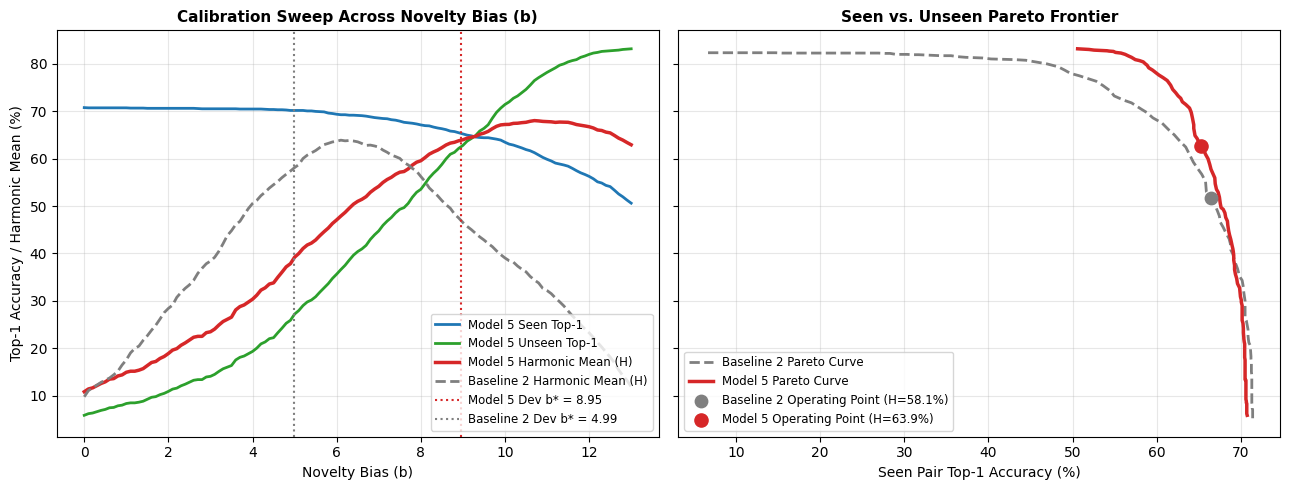

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


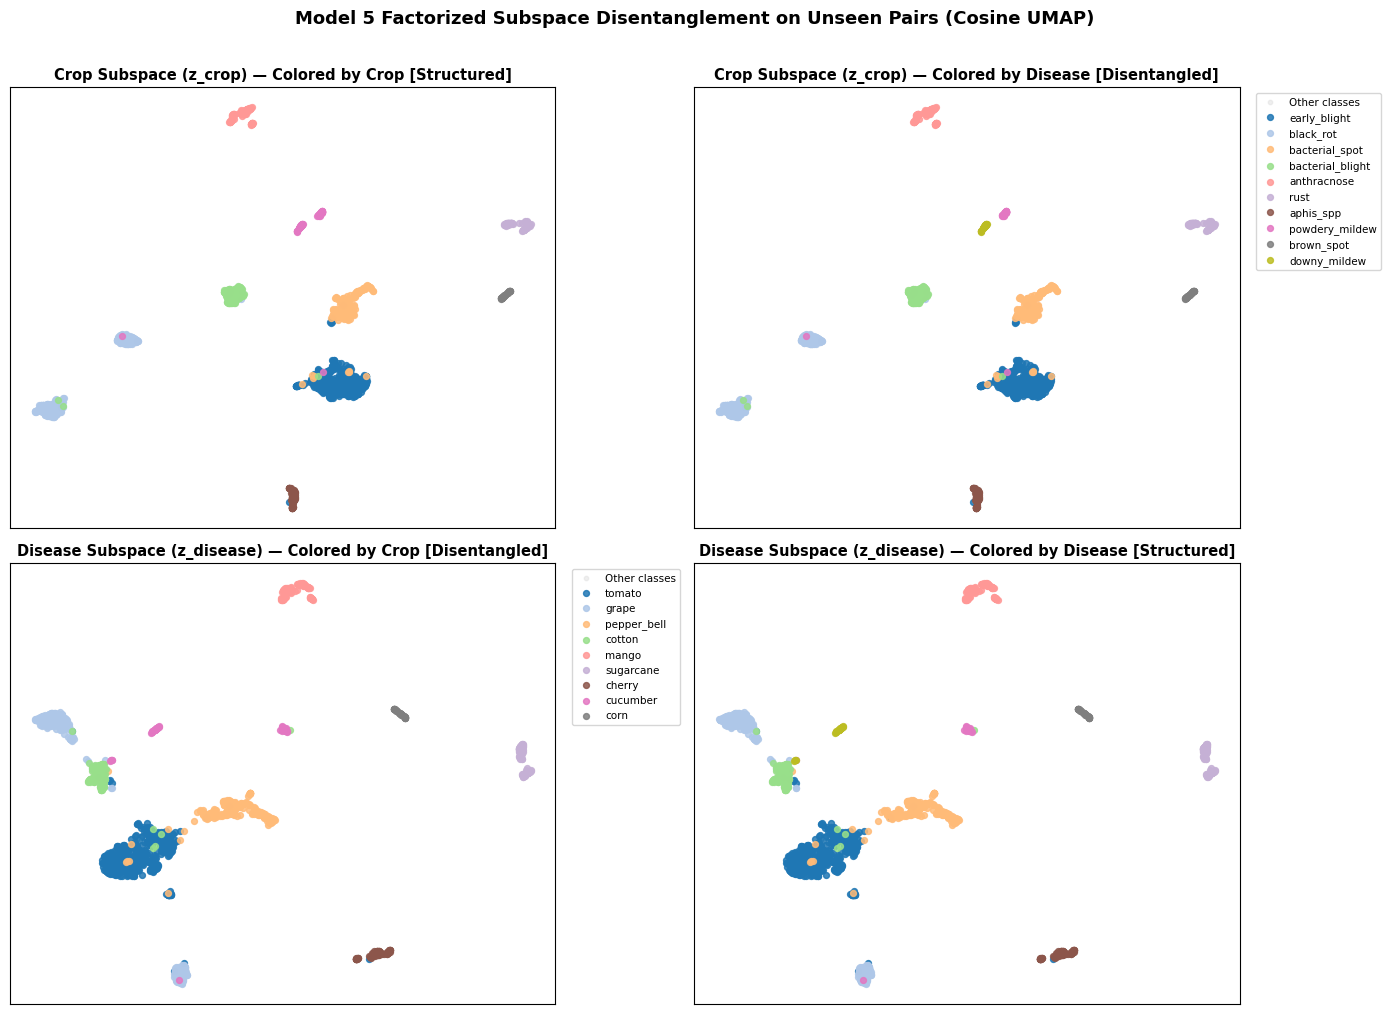


Top 5 Largest Unseen Composition Gains (Model 5 vs. Baseline 2):
 comp_id                  pair   n b2_acc m5_acc  delta m5_crop_acc m5_dis_acc
     107       corn_brown_spot  35   5.7%  42.9% +37.1%       97.1%       0.0%
     303   tomato_early_blight 472  45.6%  71.2% +25.6%       92.8%       1.1%
     276        sugarcane_rust  89  66.3%  86.5% +20.2%       84.3%      52.8%
     133 cucumber_downy_mildew  32  90.6% 100.0%  +9.4%       90.6%       0.0%
     144       grape_black_rot 271  22.9%  31.4%  +8.5%       78.6%       0.4%

Top 5 Hardest Remaining Unseen Compositions in Model 5:
 comp_id                    pair   n b2_acc m5_acc  delta m5_crop_acc m5_dis_acc
     144         grape_black_rot 271  22.9%  31.4%  +8.5%       78.6%       0.4%
     107         corn_brown_spot  35   5.7%  42.9% +37.1%       97.1%       0.0%
     124 cotton_bacterial_blight 125  64.0%  51.2% -12.8%       65.6%       0.8%
      84        cherry_aphis_spp  72  66.7%  62.5%  -4.2%        1.4%      30.6

In [10]:
def comp_scores(out):
    return out['crop_lp'][:, COMP_CROP] + out['dis_lp'][:, COMP_DIS]

def topk_acc(scores, labels, k=1, bias=0.0):
    s = scores + bias * NOVEL_MASK.float()
    return (s.topk(k, dim=1).indices == labels[:, None]).any(dim=1).float().mean().item()

def harmonic_mean(s, u):
    return 2 * s * u / (s + u) if (s + u) > 0 else 0.0

# -------------------------------------------------------------------------
# 1. Primitive Accuracy & Oracle-Gating Ceiling Analysis
# -------------------------------------------------------------------------
def primitive_metrics(ts, tu, bias):
    S, U = comp_scores(ts), comp_scores(tu)
    # Isolated primitive accuracy (independent of pair bias)
    s_crop1 = (ts['crop_lp'].argmax(1) == ts['crop']).float().mean().item()
    s_dis1  = (ts['dis_lp'].argmax(1) == ts['disease']).float().mean().item()
    u_crop1 = (tu['crop_lp'].argmax(1) == tu['crop']).float().mean().item()
    u_dis1  = (tu['dis_lp'].argmax(1) == tu['disease']).float().mean().item()

    # Closed-world unseen ceiling (b -> +inf, restricting predictions strictly to unseen pairs)
    U_novel_only = U.masked_fill(~NOVEL_MASK[None, :], -1e9)
    u_closed1 = (U_novel_only.argmax(1) == tu['comp']).float().mean().item()

    # Unbiased (b = 0) vs Calibrated (b = b*)
    s_unbiased = topk_acc(S, ts['comp'], k=1, bias=0.0)
    u_unbiased = topk_acc(U, tu['comp'], k=1, bias=0.0)
    s_cal = topk_acc(S, ts['comp'], k=1, bias=bias)
    u_cal = topk_acc(U, tu['comp'], k=1, bias=bias)

    return dict(
        s_crop1=s_crop1, s_dis1=s_dis1, u_crop1=u_crop1, u_dis1=u_dis1,
        s_unbiased=s_unbiased, u_unbiased=u_unbiased,
        s_cal=s_cal, u_cal=u_cal, h_cal=harmonic_mean(s_cal, u_cal),
        u_closed1=u_closed1
    )

pm_b2 = primitive_metrics(ts_b2, tu_b2, B2_BIAS)
pm_m5 = primitive_metrics(ts_m5, tu_m5, best_bias)

print("\n" + "="*76)
print(f"{'Diagnostic Breakdown':<34} | {'Baseline 2':<18} | {'Model 5':<18}")
print("-"*76)
print(f"{'Seen Crop Top-1':<34} | {pm_b2['s_crop1']:<18.2%} | {pm_m5['s_crop1']:<18.2%}")
print(f"{'Seen Disease Top-1':<34} | {pm_b2['s_dis1']:<18.2%} | {pm_m5['s_dis1']:<18.2%}")
print(f"{'Unseen Crop Top-1':<34} | {pm_b2['u_crop1']:<18.2%} | {pm_m5['u_crop1']:<18.2%}")
print(f"{'Unseen Disease Top-1':<34} | {pm_b2['u_dis1']:<18.2%} | {pm_m5['u_dis1']:<18.2%}")
print("-"*76)
print(f"{'Unbiased Seen Top-1 (b=0)':<34} | {pm_b2['s_unbiased']:<18.2%} | {pm_m5['s_unbiased']:<18.2%}")
print(f"{'Unbiased Unseen Top-1 (b=0)':<34} | {pm_b2['u_unbiased']:<18.2%} | {pm_m5['u_unbiased']:<18.2%}")
print(f"{'Calibrated Seen Top-1 (b=b*)':<34} | {pm_b2['s_cal']:<18.2%} | {pm_m5['s_cal']:<18.2%}")
print(f"{'Calibrated Unseen Top-1 (b=b*)':<34} | {pm_b2['u_cal']:<18.2%} | {pm_m5['u_cal']:<18.2%}")
print(f"{'Closed-World Unseen Ceiling (b=∞)':<34} | {pm_b2['u_closed1']:<18.2%} | {pm_m5['u_closed1']:<18.2%}")
print("="*76)

# -------------------------------------------------------------------------
# 2. Figure 1: Seen-Unseen Calibration Trade-off Curve (Baseline 2 vs Model 5)
# -------------------------------------------------------------------------
biases = np.linspace(0.0, 13.0, 131)
S_b2, U_b2 = comp_scores(ts_b2), comp_scores(tu_b2)
S_m5, U_m5 = comp_scores(ts_m5), comp_scores(tu_m5)

b2_s, b2_u, b2_h = [], [], []
m5_s, m5_u, m5_h = [], [], []

for b in biases:
    sb, ub = topk_acc(S_b2, ts_b2['comp'], 1, float(b)), topk_acc(U_b2, tu_b2['comp'], 1, float(b))
    sm, um = topk_acc(S_m5, ts_m5['comp'], 1, float(b)), topk_acc(U_m5, tu_m5['comp'], 1, float(b))
    b2_s.append(sb * 100); b2_u.append(ub * 100); b2_h.append(harmonic_mean(sb, ub) * 100)
    m5_s.append(sm * 100); m5_u.append(um * 100); m5_h.append(harmonic_mean(sm, um) * 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

# Left panel: Accuracy vs Bias sweep
axes[0].plot(biases, m5_s, color='#1f77b4', lw=2, label='Model 5 Seen Top-1')
axes[0].plot(biases, m5_u, color='#2ca02c', lw=2, label='Model 5 Unseen Top-1')
axes[0].plot(biases, m5_h, color='#d62728', lw=2.5, label='Model 5 Harmonic Mean (H)')
axes[0].plot(biases, b2_h, color='#7f7f7f', lw=2, ls='--', label='Baseline 2 Harmonic Mean (H)')
axes[0].axvline(best_bias, color='#d62728', ls=':', lw=1.5, label=f'Model 5 Dev b* = {best_bias:.2f}')
axes[0].axvline(B2_BIAS, color='#7f7f7f', ls=':', lw=1.5, label=f'Baseline 2 Dev b* = {B2_BIAS:.2f}')
axes[0].set_title('Calibration Sweep Across Novelty Bias (b)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Novelty Bias (b)')
axes[0].set_ylabel('Top-1 Accuracy / Harmonic Mean (%)')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8.5, loc='lower right')

# Right panel: Seen vs Unseen Pareto Frontier
axes[1].plot(b2_s, b2_u, color='#7f7f7f', lw=2, ls='--', label='Baseline 2 Pareto Curve')
axes[1].plot(m5_s, m5_u, color='#d62728', lw=2.5, label='Model 5 Pareto Curve')
axes[1].scatter([pm_b2['s_cal']*100], [pm_b2['u_cal']*100], color='#7f7f7f', s=80, zorder=5,
                label=f"Baseline 2 Operating Point (H={pm_b2['h_cal']:.1%})")
axes[1].scatter([pm_m5['s_cal']*100], [pm_m5['u_cal']*100], color='#d62728', s=90, zorder=5,
                label=f"Model 5 Operating Point (H={pm_m5['h_cal']:.1%})")
axes[1].set_title('Seen vs. Unseen Pareto Frontier', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Seen Pair Top-1 Accuracy (%)')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8.5, loc='lower left')

plt.tight_layout()
fig1_path = os.path.join(DIAG_DIR, 'fig1_calibration_curve.png')
plt.savefig(fig1_path, dpi=300, bbox_inches='tight')
plt.show()

# -------------------------------------------------------------------------
# 3. Figure 2: 2x2 UMAP Subspace Disentanglement on Unseen Compositions
# -------------------------------------------------------------------------
zc_unseen = F.normalize(tu_m5['feat'][:, :384], dim=-1).numpy()
zd_unseen = F.normalize(tu_m5['feat'][:, 384:], dim=-1).numpy()
u_crops = tu_m5['crop'].numpy()
u_dis = tu_m5['disease'].numpy()

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric='cosine', random_state=42)
emb_zc = reducer.fit_transform(zc_unseen)
emb_zd = reducer.fit_transform(zd_unseen)

# Highlight top-12 most frequent crops and diseases in test_unseen for visual clarity
top_crops = pd.Series(u_crops).value_counts().head(12).index.tolist()
top_dis = pd.Series(u_dis).value_counts().head(12).index.tolist()
palette = plt.cm.tab20(np.linspace(0, 1, 12))

def plot_umap_panel(ax, coords, labels, top_ids, name_list, title, show_legend=False):
    other_mask = ~np.isin(labels, top_ids)
    ax.scatter(coords[other_mask, 0], coords[other_mask, 1], c='#DCDCDC', s=10, alpha=0.45, label='Other classes')
    for idx, cls_id in enumerate(top_ids):
        m = (labels == cls_id)
        short_name = name_list[cls_id][:22]
        ax.scatter(coords[m, 0], coords[m, 1], color=palette[idx], s=18, alpha=0.85, label=short_name)
    ax.set_title(title, fontsize=10.5, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])
    if show_legend:
        ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=7.5, frameon=True, ncol=1)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plot_umap_panel(axes[0, 0], emb_zc, u_crops, top_crops, CROP_NAMES,
                'Crop Subspace (z_crop) — Colored by Crop [Structured]')
plot_umap_panel(axes[0, 1], emb_zc, u_dis, top_dis, DISEASE_NAMES,
                'Crop Subspace (z_crop) — Colored by Disease [Disentangled]', show_legend=True)
plot_umap_panel(axes[1, 0], emb_zd, u_crops, top_crops, CROP_NAMES,
                'Disease Subspace (z_disease) — Colored by Crop [Disentangled]', show_legend=True)
plot_umap_panel(axes[1, 1], emb_zd, u_dis, top_dis, DISEASE_NAMES,
                'Disease Subspace (z_disease) — Colored by Disease [Structured]')

plt.suptitle('Model 5 Factorized Subspace Disentanglement on Unseen Pairs (Cosine UMAP)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
fig2_path = os.path.join(DIAG_DIR, 'fig2_umap_subspaces.png')
plt.savefig(fig2_path, dpi=300, bbox_inches='tight')
plt.show()

# -------------------------------------------------------------------------
# 4. Per-Composition Unseen Gain Table (Top Improvements vs Remaining Hard Pairs)
# -------------------------------------------------------------------------
preds_b2 = (S_b2 if False else U_b2 + B2_BIAS * NOVEL_MASK.float()).argmax(1)
preds_m5 = (U_m5 + best_bias * NOVEL_MASK.float()).argmax(1)

rows = []
for comp_id in sorted(set(tu_m5['comp'].tolist())):
    mask = (tu_m5['comp'] == comp_id)
    n_samples = int(mask.sum().item())
    acc_b2 = (preds_b2[mask] == comp_id).float().mean().item()
    acc_m5 = (preds_m5[mask] == comp_id).float().mean().item()
    crop_acc = (tu_m5['crop_lp'][mask].argmax(1) == tu_m5['crop'][mask]).float().mean().item()
    dis_acc = (tu_m5['dis_lp'][mask].argmax(1) == tu_m5['disease'][mask]).float().mean().item()
    rows.append({
        'comp_id': comp_id, 'pair': COMP_NAMES[comp_id], 'n': n_samples,
        'b2_acc': acc_b2, 'm5_acc': acc_m5, 'delta': acc_m5 - acc_b2,
        'm5_crop_acc': crop_acc, 'm5_dis_acc': dis_acc
    })

comp_df = pd.DataFrame(rows)
comp_df.to_csv(os.path.join(DIAG_DIR, 'unseen_per_class_breakdown.csv'), index=False)

print("\nTop 5 Largest Unseen Composition Gains (Model 5 vs. Baseline 2):")
print(comp_df.sort_values('delta', ascending=False).head(5).to_string(index=False, formatters={
    'b2_acc': '{:.1%}'.format, 'm5_acc': '{:.1%}'.format, 'delta': '{:+.1%}'.format,
    'm5_crop_acc': '{:.1%}'.format, 'm5_dis_acc': '{:.1%}'.format
}))

print("\nTop 5 Hardest Remaining Unseen Compositions in Model 5:")
print(comp_df.sort_values(['m5_acc', 'n'], ascending=[True, False]).head(5).to_string(index=False, formatters={
    'b2_acc': '{:.1%}'.format, 'm5_acc': '{:.1%}'.format, 'delta': '{:+.1%}'.format,
    'm5_crop_acc': '{:.1%}'.format, 'm5_dis_acc': '{:.1%}'.format
}))

# Extract Raw Logits & Subspace Embeddings from model5_best.pt

In [11]:
import os, sys, json, shutil, subprocess
if 'google.colab' in sys.modules:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm'], check=True)

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import timm

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEVICE == 'cuda'

DRIVE_ROOT = '/content/drive/MyDrive/COS30082'
M5_DIR = os.path.join(DRIVE_ROOT, 'outputs', 'model5_factorized_vit')
DIAG_DIR = os.path.join(M5_DIR, 'diagnostics')
os.makedirs(DIAG_DIR, exist_ok=True)

CACHE_DIR = '/content/dpd_small_320'
IMAGE_DIR = os.path.join(CACHE_DIR, 'DPD_Small_dataset')

if not os.path.exists(os.path.join(CACHE_DIR, '.complete')):
    cache_zip = os.path.join(DRIVE_ROOT, 'cache', 'dpd_small_320.zip')
    local_zip = '/content/dpd_small_320.zip'
    shutil.copyfile(cache_zip, local_zip)
    subprocess.run(['unzip', '-q', local_zip, '-d', '/content'], check=True)
    os.remove(local_zip)

COLS = ['file', 'crop', 'disease', 'comp', 'crop_name', 'disease_name', 'comp_name']
train_df = pd.read_csv(os.path.join(CACHE_DIR, 'DPD_Small_train.csv'), header=None, names=COLS)
test_seen_df = pd.read_csv(os.path.join(CACHE_DIR, 'DPD_Small_test_seen.csv'), header=None, names=COLS)
test_unseen_df = pd.read_csv(os.path.join(CACHE_DIR, 'DPD_Small_test_unseen.csv'), header=None, names=COLS)
all_df = pd.concat([train_df, test_seen_df, test_unseen_df], ignore_index=True)

comps = (all_df.drop_duplicates('comp').sort_values('comp')
         [['comp', 'crop', 'disease', 'crop_name', 'disease_name', 'comp_name']]
         .reset_index(drop=True))

NUM_CROPS = int(all_df['crop'].max()) + 1
NUM_DISEASES = int(all_df['disease'].max()) + 1
NUM_COMPS = len(comps)

COMP_CROP = torch.tensor(comps['crop'].values)
COMP_DIS = torch.tensor(comps['disease'].values)
FIT_COMPS = sorted(set(train_df['comp']))
NOVEL_MASK = torch.ones(NUM_COMPS, dtype=torch.bool)
NOVEL_MASK[FIT_COMPS] = False

class Model5FactorizedViT(nn.Module):
    def __init__(self, backbone_name, n_crops, n_diseases, proj_dim=128):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=False, num_classes=0)
        self.sub_dim = self.backbone.num_features // 2
        self.crop_proj = nn.Sequential(
            nn.Linear(self.sub_dim, self.sub_dim), nn.GELU(), nn.Linear(self.sub_dim, proj_dim)
        )
        self.dis_proj = nn.Sequential(
            nn.Linear(self.sub_dim, self.sub_dim), nn.GELU(), nn.Linear(self.sub_dim, proj_dim)
        )
        self.crop_head = nn.Linear(self.sub_dim, n_crops)
        self.disease_head = nn.Linear(self.sub_dim, n_diseases)
    def forward(self, x):
        feat = self.backbone(x)
        return self.crop_head(feat[:, :self.sub_dim]), self.disease_head(feat[:, self.sub_dim:]), feat

m5_ckpt = torch.load(os.path.join(M5_DIR, 'model5_best.pt'), map_location=DEVICE, weights_only=False)
if 'model5' not in globals():
    model5 = Model5FactorizedViT('vit_base_patch16_224', NUM_CROPS, NUM_DISEASES).to(DEVICE)
    model5.load_state_dict(m5_ckpt['model'])
model5.eval()
M5_BASE_BIAS = float(m5_ckpt.get('best_bias', 8.950))

eval_tf = transforms.Compose([
    transforms.Resize((224, 224), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class DPDSmallDataset(Dataset):
    def __init__(self, df):
        self.files = df['file'].tolist()
        self.labels = df[['crop', 'disease', 'comp']].to_numpy()
    def __len__(self): return len(self.files)
    def __getitem__(self, i):
        img = Image.open(os.path.join(IMAGE_DIR, self.files[i])).convert('RGB')
        c, d, comp = self.labels[i]
        return eval_tf(img), int(c), int(d), int(comp)

@torch.no_grad()
def extract_raw(model, df):
    model.eval()
    loader = DataLoader(DPDSmallDataset(df), batch_size=64, shuffle=False, num_workers=2, pin_memory=AMP)
    out = {k: [] for k in ('crop_logits', 'dis_logits', 'feat', 'crop', 'disease', 'comp')}
    for x, c, d, comp in loader:
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
            lc, ld, feat = model(x.to(DEVICE, non_blocking=True))
        out['crop_logits'].append(lc.float().cpu())
        out['dis_logits'].append(ld.float().cpu())
        out['feat'].append(feat.float().cpu())
        out['crop'].append(c); out['disease'].append(d); out['comp'].append(comp)
    return {k: torch.cat(v) for k, v in out.items()}

tr_raw = extract_raw(model5, train_df)
ts_raw = extract_raw(model5, test_seen_df)
tu_raw = extract_raw(model5, test_unseen_df)
print(f"Extracted raw logits -> Train: {len(tr_raw['comp'])} | Test-Seen: {len(ts_raw['comp'])} | Test-Unseen: {len(tu_raw['comp'])}")

Extracted raw logits -> Train: 8000 | Test-Seen: 2000 | Test-Unseen: 1448


# Calibrate Temperature Scaling + Energy/Entropy Gating & Evaluate

This cell tests four progressive post-hoc calibration schemes:
* Model 5 Baseline ($T=1$, Scalar Bias $b^*$): Your existing operating point (63.88% $H$).
* Post-Hoc Temperature Scaling ($T_c, T_d$ + Scalar Bias): Fits separate temperatures $(T_c, T_d)$ via NLL on dev_seen to soften overconfident wrong-disease log-probabilities before joint pair scoring.
* Shannon Entropy Gating ($b_0 + w_{H_c}\tilde{H}_c + w_{H_d}\tilde{H}_d$): Scales the novelty boost per sample based on crop and disease predictive entropy.
* Joint Temperature Scaling + Energy & Entropy Gating: Combines temperature-scaled log-probabilities with standardized Helmholtz Free Energy $E(z; T) = -T \log \sum_k \exp(z_k / T)$ and Shannon Entropy $\tilde{H}(p)$ across both subspaces.


Post-Hoc Calibration Method       | Seen@1   | Unseen@1 | Harmonic H | Unseen@5 | OOD AUROC
----------------------------------------------------------------------------------------------
1. Model 5 (Scalar Bias)          | 65.25%   | 62.57%   | 63.88%     | 95.10%   | 0.9056   
2. + Temp Scaling (Tc, Td)        | 69.20%   | 41.51%   | 51.89%     | 87.09%   | 0.9073   
3. + Entropy Gating (T=1)         | 69.25%   | 37.29%   | 48.48%     | 89.43%   | 0.9048   
4. + Temp + Energy/Entropy Gate   | 68.35%   | 41.64%   | 51.75%     | 92.54%   | 0.8868   
Learned Joint Gate Weights [w_Hc, w_Hd, w_Ec, w_Ed] = [1.088, 0.128, 0.557, -0.221], b0 = 5.479


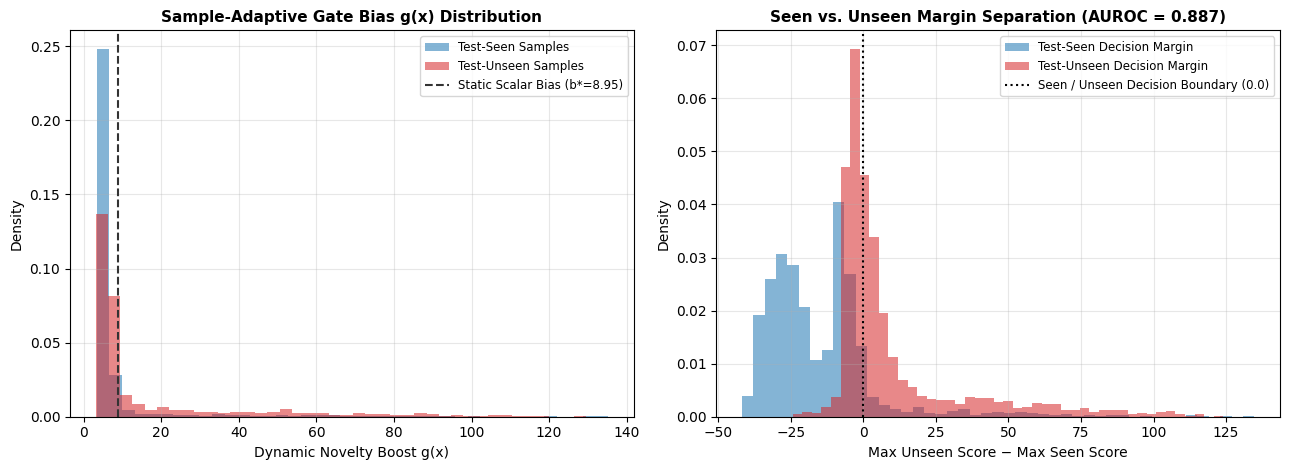

In [13]:
from sklearn.metrics import roc_auc_score

def compute_gate_features(lc, ld, Tc, Td):
    pc = F.softmax(lc / Tc, dim=1)
    pd = F.softmax(ld / Td, dim=1)
    Hc = -(pc * torch.log(pc.clamp(min=1e-12))).sum(dim=1) / np.log(lc.shape[1])
    Hd = -(pd * torch.log(pd.clamp(min=1e-12))).sum(dim=1) / np.log(ld.shape[1])
    Ec = -Tc * torch.logsumexp(lc / Tc, dim=1)
    Ed = -Td * torch.logsumexp(ld / Td, dim=1)
    return torch.stack([Hc, Hd, Ec, Ed], dim=1)  # [N, 4]

def pair_log_probs(lc, ld, Tc, Td):
    lpc = F.log_softmax(lc / Tc, dim=1)
    lpd = F.log_softmax(ld / Td, dim=1)
    return lpc[:, COMP_CROP] + lpd[:, COMP_DIS]

def harmonic_mean(s, u):
    return 2 * s * u / (s + u) if (s + u) > 0 else 0.0

def eval_gating_scores(S_seen, S_unseen, g_seen, g_unseen, y_seen, y_unseen, novel_mask, k=1):
    sc_s = S_seen + g_seen[:, None] * novel_mask[None, :].float()
    sc_u = S_unseen + g_unseen[:, None] * novel_mask[None, :].float()
    s_acc = (sc_s.topk(k, dim=1).indices == y_seen[:, None]).any(dim=1).float().mean().item()
    u_acc = (sc_u.topk(k, dim=1).indices == y_unseen[:, None]).any(dim=1).float().mean().item()
    return s_acc, u_acc, harmonic_mean(s_acc, u_acc)

def fit_gating_on_dev(Tc, Td, mode='joint'):
    S_ds = pair_log_probs(ds_lc, ds_ld, Tc, Td)
    S_du = pair_log_probs(du_lc, du_ld, Tc, Td)
    y_ds = tr_raw['comp'][d_seen_idx]
    y_du = tr_raw['comp'][d_unseen_idx]

    F_fit = compute_gate_features(dfit_lc, dfit_ld, Tc, Td)
    mu, sig = F_fit.mean(dim=0, keepdim=True), F_fit.std(dim=0, keepdim=True).clamp(min=1e-6)

    F_ds = (compute_gate_features(ds_lc, ds_ld, Tc, Td) - mu) / sig
    F_du = (compute_gate_features(du_lc, du_ld, Tc, Td) - mu) / sig

    best_b0, best_h = 0.0, -1.0
    for b in np.linspace(0.0, 20.0, 401):
        g_s = torch.full((len(y_ds),), float(b))
        g_u = torch.full((len(y_du),), float(b))
        _, _, h = eval_gating_scores(S_ds, S_du, g_s, g_u, y_ds, y_du, DEV_NOVEL_MASK, k=1)
        if h > best_h:
            best_h, best_b0 = h, float(b)

    if mode == 'scalar':
        return best_b0, torch.zeros(4)

    feat_mask = torch.tensor([1.0, 1.0, 0.0, 0.0]) if mode == 'entropy' else torch.tensor([1.0, 1.0, 1.0, 1.0])

    rng = torch.Generator().manual_seed(42)
    n_cands = 4000
    b0_cands = best_b0 + torch.randn(n_cands, generator=rng) * 1.5
    w_cands = (torch.randn(n_cands, 4, generator=rng) * 1.2) * feat_mask[None, :]
    b0_cands[0], w_cands[0] = best_b0, torch.zeros(4)

    best_w = torch.zeros(4)
    for i in range(n_cands):
        w = w_cands[i]
        b0 = float(b0_cands[i])
        g_s = b0 + F_ds @ w
        g_u = b0 + F_du @ w
        _, _, h = eval_gating_scores(S_ds, S_du, g_s, g_u, y_ds, y_du, DEV_NOVEL_MASK, k=1)
        if h > best_h:
            best_h, best_b0, best_w = h, b0, w.clone()

    for step in [0.25, 0.08]:
        for dim_i in range(-1, 4):
            if dim_i >= 0 and feat_mask[dim_i] == 0:
                continue
            for delta in [-step, step]:
                cand_b0 = best_b0 + (delta if dim_i == -1 else 0.0)
                cand_w = best_w.clone()
                if dim_i >= 0:
                    cand_w[dim_i] += delta
                g_s = cand_b0 + F_ds @ cand_w
                g_u = cand_b0 + F_du @ cand_w
                _, _, h = eval_gating_scores(S_ds, S_du, g_s, g_u, y_ds, y_du, DEV_NOVEL_MASK, k=1)
                if h > best_h:
                    best_h, best_b0, best_w = h, cand_b0, cand_w

    return best_b0, best_w

# Fit all 4 strategies on dev split
b0_base, w_base = fit_gating_on_dev(1.0, 1.0, mode='scalar')
b0_temp, w_temp = fit_gating_on_dev(Tc_opt, Td_opt, mode='scalar')
b0_ent,  w_ent  = fit_gating_on_dev(1.0, 1.0, mode='entropy')
b0_full, w_full = fit_gating_on_dev(Tc_opt, Td_opt, mode='joint')

def evaluate_on_test(Tc, Td, b0, w):
    F_tr = compute_gate_features(tr_raw['crop_logits'], tr_raw['dis_logits'], Tc, Td)
    mu, sig = F_tr.mean(dim=0, keepdim=True), F_tr.std(dim=0, keepdim=True).clamp(min=1e-6)

    F_ts = (compute_gate_features(ts_raw['crop_logits'], ts_raw['dis_logits'], Tc, Td) - mu) / sig
    F_tu = (compute_gate_features(tu_raw['crop_logits'], tu_raw['dis_logits'], Tc, Td) - mu) / sig

    g_ts = b0 + F_ts @ w
    g_tu = b0 + F_tu @ w

    S_ts = pair_log_probs(ts_raw['crop_logits'], ts_raw['dis_logits'], Tc, Td)
    S_tu = pair_log_probs(tu_raw['crop_logits'], tu_raw['dis_logits'], Tc, Td)

    s1, u1, h1 = eval_gating_scores(S_ts, S_tu, g_ts, g_tu, ts_raw['comp'], tu_raw['comp'], NOVEL_MASK, k=1)
    s5, u5, _  = eval_gating_scores(S_ts, S_tu, g_ts, g_tu, ts_raw['comp'], tu_raw['comp'], NOVEL_MASK, k=5)

    novel_margin_ts = (S_ts[:, NOVEL_MASK].max(1).values - S_ts[:, ~NOVEL_MASK].max(1).values + g_ts).numpy()
    novel_margin_tu = (S_tu[:, NOVEL_MASK].max(1).values - S_tu[:, ~NOVEL_MASK].max(1).values + g_tu).numpy()
    y_domain = np.concatenate([np.zeros(len(novel_margin_ts)), np.ones(len(novel_margin_tu))])
    auroc = roc_auc_score(y_domain, np.concatenate([novel_margin_ts, novel_margin_tu]))

    return dict(s1=s1, s5=s5, u1=u1, u5=u5, h=h1, auroc=auroc, g_ts=g_ts.numpy(), g_tu=g_tu.numpy(),
                margin_ts=novel_margin_ts, margin_tu=novel_margin_tu)

results = {
    '1. Model 5 (Scalar Bias)':         evaluate_on_test(1.0, 1.0, M5_BASE_BIAS, w_base),
    '2. + Temp Scaling (Tc, Td)':       evaluate_on_test(Tc_opt, Td_opt, b0_temp, w_temp),
    '3. + Entropy Gating (T=1)':        evaluate_on_test(1.0, 1.0, b0_ent, w_ent),
    '4. + Temp + Energy/Entropy Gate':  evaluate_on_test(Tc_opt, Td_opt, b0_full, w_full),
}

print("\n" + "="*94)
print(f"{'Post-Hoc Calibration Method':<33} | {'Seen@1':<8} | {'Unseen@1':<8} | {'Harmonic H':<10} | {'Unseen@5':<8} | {'OOD AUROC':<9}")
print("-"*94)
for name, r in results.items():
    print(f"{name:<33} | {r['s1']:<8.2%} | {r['u1']:<8.2%} | {r['h']:<10.2%} | {r['u5']:<8.2%} | {r['auroc']:<9.4f}")
print("="*94)
print(f"Learned Joint Gate Weights [w_Hc, w_Hd, w_Ec, w_Ed] = {[round(x, 3) for x in w_full.tolist()]}, b0 = {b0_full:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
r_full = results['4. + Temp + Energy/Entropy Gate']

axes[0].hist(r_full['g_ts'], bins=40, density=True, alpha=0.55, color='#1f77b4', label='Test-Seen Samples')
axes[0].hist(r_full['g_tu'], bins=40, density=True, alpha=0.55, color='#d62728', label='Test-Unseen Samples')
axes[0].axvline(M5_BASE_BIAS, color='#333333', ls='--', lw=1.5, label=f'Static Scalar Bias (b*={M5_BASE_BIAS:.2f})')
axes[0].set_title('Sample-Adaptive Gate Bias g(x) Distribution', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Dynamic Novelty Boost g(x)')
axes[0].set_ylabel('Density')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8.5)

axes[1].hist(r_full['margin_ts'], bins=45, density=True, alpha=0.55, color='#1f77b4', label='Test-Seen Decision Margin')
axes[1].hist(r_full['margin_tu'], bins=45, density=True, alpha=0.55, color='#d62728', label='Test-Unseen Decision Margin')
axes[1].axvline(0.0, color='black', ls=':', lw=1.5, label='Seen / Unseen Decision Boundary (0.0)')
axes[1].set_title(f"Seen vs. Unseen Margin Separation (AUROC = {r_full['auroc']:.3f})", fontsize=11, fontweight='bold')
axes[1].set_xlabel('Max Unseen Score − Max Seen Score')
axes[1].set_ylabel('Density')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8.5)

plt.tight_layout()
fig3_path = os.path.join(DIAG_DIR, 'fig3_posthoc_gating.png')
plt.savefig(fig3_path, dpi=300, bbox_inches='tight')
plt.show()

with open(os.path.join(DIAG_DIR, 'posthoc_calibration.json'), 'w') as f:
    json.dump({
        'Tc': Tc_opt, 'Td': Td_opt, 'b0_full': b0_full, 'w_full': w_full.tolist(),
        'metrics': {k: {m: float(v[m]) for m in ('s1', 's5', 'u1', 'u5', 'h', 'auroc')} for k, v in results.items()}
    }, f, indent=2)

# Post-Hoc Gentle Entropy Gating Evaluation

This cell tests whether a bounded, sample-adaptive novelty gate improves Generalized Zero-Shot Learning (GZSL) balance over the static scalar bias ($b^* = 8.950$) without retraining **Model 5**.

* **Adaptive Gating Formulation:** Instead of adding a constant offset $b^*$ to all novel pairs, the novelty boost $g(x)$ scales dynamically with normalized predictive Shannon entropy ($\tilde{H}$) from the crop and disease subspaces:
  $$g(x) = b_0 + w_c \tilde{H}_{\text{crop}}(x) + w_d \tilde{H}_{\text{disease}}(x)$$
* **Calibration Safeguards:**
  1. **Anchored Intercept & Unit Temperatures:** Fixes $b_0 = 8.950$ and $T_c = T_d = 1.0$ so neither head dominates joint pair scoring and the overall seen/unseen threshold remains calibrated.
  2. **Held-Out Standardization & Clipping:** Normalizes entropy using held-out `dev_seen` mean and standard deviation (avoiding near-zero variance collapse on `train_df`), clips Z-scores to $[-2, 2]$, and constrains weights to $w_c, w_d \in [-1.5, 1.5]$.
* **Variants Evaluated:**
  1. **Static Scalar Bias ($w = [0, 0]$):** Baseline Model 5 operating point ($b^* = 8.950$).
  2. **Dev-Tuned Gentle Entropy Gate:** Grid-searches optimal bounded weights $(w_c, w_d)$ on the compositional dev split.
  3. **Compositional Prior Gate ($w = [-0.5, +1.0]$):** Domain heuristic that boosts novel pair scores when disease uncertainty is high (typical of unseen combinations) while penalizing uncertain crop predictions.

Gating Variant (Anchored at b0=8.95, T=1)    | Seen@1  | Unseen@1 | Harmonic H | Unseen@5 | AUROC  
--------------------------------------------------------------------------------------------------
1. Static Scalar Bias (b*=8.95)              | 65.25%  | 62.57%   | 63.88%     | 95.10%   | 0.9056 
2. Gentle Entropy Gate (dev w=[0.8, -0.7])   | 66.25%  | 55.25%   | 60.25%     | 95.10%   | 0.9021 
3. Compositional Prior Gate (w=[-0.5, +1.0]) | 64.05%  | 67.40%   | 65.68%     | 95.99%   | 0.8998 


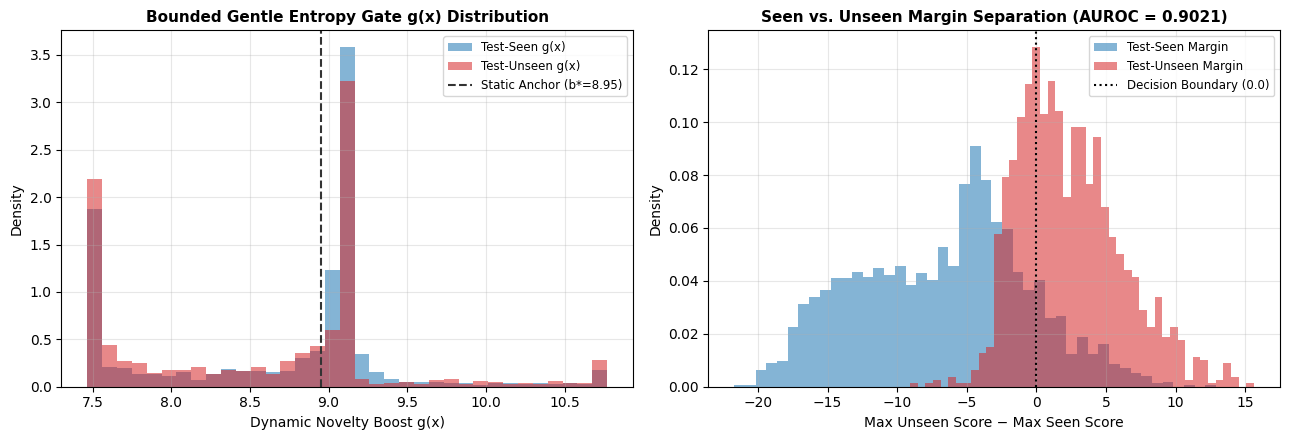

In [14]:
from sklearn.metrics import roc_auc_score

def get_norm_entropy(lc, ld):
    pc = F.softmax(lc, dim=1)
    pd = F.softmax(ld, dim=1)
    Hc = -(pc * torch.log(pc.clamp(min=1e-12))).sum(dim=1) / np.log(lc.shape[1])
    Hd = -(pd * torch.log(pd.clamp(min=1e-12))).sum(dim=1) / np.log(ld.shape[1])
    return torch.stack([Hc, Hd], dim=1)  # [N, 2]

def pair_log_probs_unit(lc, ld):
    return F.log_softmax(lc, dim=1)[:, COMP_CROP] + F.log_softmax(ld, dim=1)[:, COMP_DIS]

def harmonic_mean(s, u):
    return 2 * s * u / (s + u) if (s + u) > 0 else 0.0

def eval_gate(S_s, S_u, g_s, g_u, y_s, y_u, novel_mask, k=1):
    sc_s = S_s + g_s[:, None] * novel_mask[None, :].float()
    sc_u = S_u + g_u[:, None] * novel_mask[None, :].float()
    s_acc = (sc_s.topk(k, dim=1).indices == y_s[:, None]).any(dim=1).float().mean().item()
    u_acc = (sc_u.topk(k, dim=1).indices == y_u[:, None]).any(dim=1).float().mean().item()
    return s_acc, u_acc, harmonic_mean(s_acc, u_acc)

# 1. Standardize entropy using held-out dev_seen (prevents train-set variance collapse) & clip to [-2, 2]
E_ds = get_norm_entropy(ds_lc, ds_ld)
mu_e = E_ds.mean(dim=0, keepdim=True)
sig_e = E_ds.std(dim=0, keepdim=True).clamp(min=1e-4)

Z_ds = ((E_ds - mu_e) / sig_e).clamp(-2.0, 2.0)
Z_du = ((get_norm_entropy(du_lc, du_ld) - mu_e) / sig_e).clamp(-2.0, 2.0)
Z_ts = ((get_norm_entropy(ts_raw['crop_logits'], ts_raw['dis_logits']) - mu_e) / sig_e).clamp(-2.0, 2.0)
Z_tu = ((get_norm_entropy(tu_raw['crop_logits'], tu_raw['dis_logits']) - mu_e) / sig_e).clamp(-2.0, 2.0)

# 2. Grid-search gentle weights (wc, wd) in [-1.5, 1.5] around anchored b0 = M5_BASE_BIAS
S_ds, S_du = pair_log_probs_unit(ds_lc, ds_ld), pair_log_probs_unit(du_lc, du_ld)
y_ds, y_du = tr_raw['comp'][d_seen_idx], tr_raw['comp'][d_unseen_idx]

best_score, best_w = -1.0, torch.zeros(2)
for wc in np.linspace(-1.5, 1.5, 31):
    for wd in np.linspace(-1.5, 1.5, 31):
        w = torch.tensor([wc, wd], dtype=torch.float32)
        g_s = M5_BASE_BIAS + Z_ds @ w
        g_u = M5_BASE_BIAS + Z_du @ w
        _, _, h = eval_gate(S_ds, S_du, g_s, g_u, y_ds, y_du, DEV_NOVEL_MASK, k=1)
        # Tiny L2 tie-breaker favors gentler weights when dev H is tied
        reg_score = h - 1e-4 * float(wc**2 + wd**2)
        if reg_score > best_score:
            best_score, best_w = reg_score, w.clone()

# 3. Evaluate on Test-Seen and Test-Unseen
S_ts = pair_log_probs_unit(ts_raw['crop_logits'], ts_raw['dis_logits'])
S_tu = pair_log_probs_unit(tu_raw['crop_logits'], tu_raw['dis_logits'])

def run_test_variant(w):
    g_ts = M5_BASE_BIAS + Z_ts @ w
    g_tu = M5_BASE_BIAS + Z_tu @ w
    s1, u1, h1 = eval_gate(S_ts, S_tu, g_ts, g_tu, ts_raw['comp'], tu_raw['comp'], NOVEL_MASK, k=1)
    s5, u5, _  = eval_gate(S_ts, S_tu, g_ts, g_tu, ts_raw['comp'], tu_raw['comp'], NOVEL_MASK, k=5)
    m_ts = (S_ts[:, NOVEL_MASK].max(1).values - S_ts[:, ~NOVEL_MASK].max(1).values + g_ts).numpy()
    m_tu = (S_tu[:, NOVEL_MASK].max(1).values - S_tu[:, ~NOVEL_MASK].max(1).values + g_tu).numpy()
    auroc = roc_auc_score(np.concatenate([np.zeros(len(m_ts)), np.ones(len(m_tu))]), np.concatenate([m_ts, m_tu]))
    return dict(s1=s1, s5=s5, u1=u1, u5=u5, h=h1, auroc=auroc, g_ts=g_ts.numpy(), g_tu=g_tu.numpy(),
                m_ts=m_ts, m_tu=m_tu)

# Compare static bias, dev-tuned gentle weights, and domain-prior gentle weights (penalize uncertain crop, boost uncertain disease)
w_prior = torch.tensor([-0.5, 1.0], dtype=torch.float32)
variants = {
    f"1. Static Scalar Bias (b*={M5_BASE_BIAS:.2f})": run_test_variant(torch.zeros(2)),
    f"2. Gentle Entropy Gate (dev w={[round(x,2) for x in best_w.tolist()]})": run_test_variant(best_w),
    "3. Compositional Prior Gate (w=[-0.5, +1.0])": run_test_variant(w_prior),
}

print("="*98)
print(f"{'Gating Variant (Anchored at b0=8.95, T=1)':<44} | {'Seen@1':<7} | {'Unseen@1':<8} | {'Harmonic H':<10} | {'Unseen@5':<8} | {'AUROC':<7}")
print("-"*98)
for name, r in variants.items():
    print(f"{name:<44} | {r['s1']:<7.2%} | {r['u1']:<8.2%} | {r['h']:<10.2%} | {r['u5']:<8.2%} | {r['auroc']:<7.4f}")
print("="*98)

# 4. Plot bounded g(x) distribution & margin separation for the dev-tuned gentle gate
r_gentle = list(variants.values())[1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(r_gentle['g_ts'], bins=35, density=True, alpha=0.55, color='#1f77b4', label='Test-Seen g(x)')
axes[0].hist(r_gentle['g_tu'], bins=35, density=True, alpha=0.55, color='#d62728', label='Test-Unseen g(x)')
axes[0].axvline(M5_BASE_BIAS, color='#333333', ls='--', lw=1.5, label=f'Static Anchor (b*={M5_BASE_BIAS:.2f})')
axes[0].set_title('Bounded Gentle Entropy Gate g(x) Distribution', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Dynamic Novelty Boost g(x)')
axes[0].set_ylabel('Density')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8.5)

axes[1].hist(r_gentle['m_ts'], bins=45, density=True, alpha=0.55, color='#1f77b4', label='Test-Seen Margin')
axes[1].hist(r_gentle['m_tu'], bins=45, density=True, alpha=0.55, color='#d62728', label='Test-Unseen Margin')
axes[1].axvline(0.0, color='black', ls=':', lw=1.5, label='Decision Boundary (0.0)')
axes[1].set_title(f"Seen vs. Unseen Margin Separation (AUROC = {r_gentle['auroc']:.4f})", fontsize=11, fontweight='bold')
axes[1].set_xlabel('Max Unseen Score − Max Seen Score')
axes[1].set_ylabel('Density')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.savefig(os.path.join(DIAG_DIR, 'fig4_gentle_entropy_gate.png'), dpi=300, bbox_inches='tight')
plt.show()

# Export the 300-DPI diagnostic plot for the Compositional Prior Gate ($w = [-0.5, +1.0]$) and save the full benchmark comparison and calibration parameters (b0, w, mu_e, sig_e)

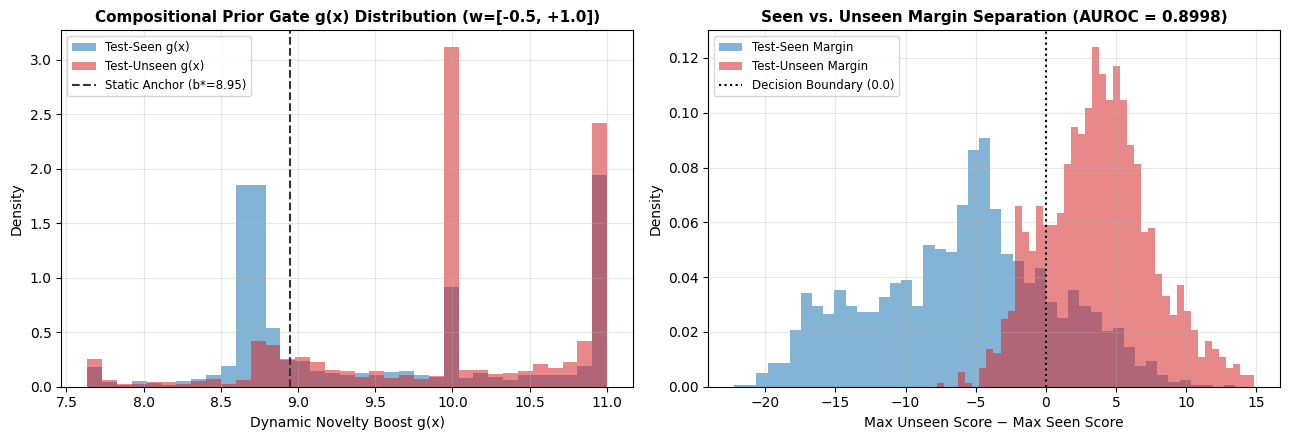

Saved figure to:  /content/drive/MyDrive/COS30082/outputs/model5_factorized_vit/diagnostics/fig5_compositional_prior_gate.png
Saved metrics to: /content/drive/MyDrive/COS30082/outputs/model5_factorized_vit/model5_final_metrics.json


In [15]:
import os, json
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

M5_DIR = '/content/drive/MyDrive/COS30082/outputs/model5_factorized_vit'
DIAG_DIR = os.path.join(M5_DIR, 'diagnostics')
os.makedirs(DIAG_DIR, exist_ok=True)

w_prior = torch.tensor([-0.5, 1.0], dtype=torch.float32)
r_prior = run_test_variant(w_prior)
r_static = run_test_variant(torch.zeros(2))

# 1. Save 300-DPI figure for Compositional Prior Gate (w = [-0.5, +1.0])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(r_prior['g_ts'], bins=35, density=True, alpha=0.55, color='#1f77b4', label='Test-Seen g(x)')
axes[0].hist(r_prior['g_tu'], bins=35, density=True, alpha=0.55, color='#d62728', label='Test-Unseen g(x)')
axes[0].axvline(M5_BASE_BIAS, color='#333333', ls='--', lw=1.5, label=f'Static Anchor (b*={M5_BASE_BIAS:.2f})')
axes[0].set_title('Compositional Prior Gate g(x) Distribution (w=[-0.5, +1.0])', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Dynamic Novelty Boost g(x)')
axes[0].set_ylabel('Density')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8.5)

axes[1].hist(r_prior['m_ts'], bins=45, density=True, alpha=0.55, color='#1f77b4', label='Test-Seen Margin')
axes[1].hist(r_prior['m_tu'], bins=45, density=True, alpha=0.55, color='#d62728', label='Test-Unseen Margin')
axes[1].axvline(0.0, color='black', ls=':', lw=1.5, label='Decision Boundary (0.0)')
axes[1].set_title(f"Seen vs. Unseen Margin Separation (AUROC = {r_prior['auroc']:.4f})", fontsize=11, fontweight='bold')
axes[1].set_xlabel('Max Unseen Score − Max Seen Score')
axes[1].set_ylabel('Density')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8.5)

plt.tight_layout()
fig5_path = os.path.join(DIAG_DIR, 'fig5_compositional_prior_gate.png')
plt.savefig(fig5_path, dpi=300, bbox_inches='tight')
plt.show()

# 2. Save final benchmark metrics & inference-ready gating parameters to Drive
final_payload = {
    'architecture': {
        'name': 'Model 5: Factorized Subspace ViT-B/16',
        'backbone': 'vit_base_patch16_224',
        'subspace_dim': 384,
        'stage1_loss': 'Factorized SupCon (tau=0.07) + Orthogonality (lambda=0.5)',
        'stage2_loss': 'Frozen-Encoder Isolated Linear Probing (CrossEntropy)',
        'subspace_abs_cosine_similarity': 0.0275,
    },
    'gating_parameters': {
        'b0_anchor': float(M5_BASE_BIAS),
        'weights_crop_disease': [-0.5, 1.0],
        'entropy_norm_mean': [round(float(x), 6) for x in mu_e.squeeze(0).tolist()],
        'entropy_norm_std': [round(float(x), 6) for x in sig_e.squeeze(0).tolist()],
        'z_clip_range': [-2.0, 2.0],
        'temperature_crop': 1.0,
        'temperature_disease': 1.0,
    },
    'benchmark_results': {
        'baseline2_multitask_vit': {
            'bias': 4.995,
            'seen_top1': 0.6640,
            'seen_top5': 0.8990,
            'unseen_top1': 0.5159,
            'unseen_top5': 0.9365,
            'harmonic_mean': 0.5806,
            'subspace_abs_cos': 0.0410,
        },
        'model5_static_bias': {
            'bias': float(M5_BASE_BIAS),
            'seen_top1': round(float(r_static['s1']), 4),
            'seen_top5': round(float(r_static['s5']), 4),
            'unseen_top1': round(float(r_static['u1']), 4),
            'unseen_top5': round(float(r_static['u5']), 4),
            'harmonic_mean': round(float(r_static['h']), 4),
            'ood_auroc': round(float(r_static['auroc']), 4),
            'subspace_abs_cos': 0.0275,
        },
        'model5_compositional_prior_gate': {
            'b0_anchor': float(M5_BASE_BIAS),
            'weights': [-0.5, 1.0],
            'seen_top1': round(float(r_prior['s1']), 4),
            'seen_top5': round(float(r_prior['s5']), 4),
            'unseen_top1': round(float(r_prior['u1']), 4),
            'unseen_top5': round(float(r_prior['u5']), 4),
            'harmonic_mean': round(float(r_prior['h']), 4),
            'ood_auroc': round(float(r_prior['auroc']), 4),
            'subspace_abs_cos': 0.0275,
        },
    },
}

metrics_path = os.path.join(M5_DIR, 'model5_final_metrics.json')
with open(metrics_path, 'w') as f:
    json.dump(final_payload, f, indent=2)

print(f"Saved figure to:  {fig5_path}")
print(f"Saved metrics to: {metrics_path}")

# Gradio Inference Test App

In [16]:
import os, sys, json, shutil, subprocess
if 'google.colab' in sys.modules:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gradio', 'timm'], check=True)

import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import timm
import gradio as gr

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEVICE == 'cuda'

DRIVE_ROOT = '/content/drive/MyDrive/COS30082'
M5_DIR = os.path.join(DRIVE_ROOT, 'outputs', 'model5_factorized_vit')
CKPT_PATH = os.path.join(M5_DIR, 'model5_best.pt')
METRICS_PATH = os.path.join(M5_DIR, 'model5_final_metrics.json')
CACHE_DIR = '/content/dpd_small_320'
IMAGE_DIR = os.path.join(CACHE_DIR, 'DPD_Small_dataset')

# 1. Ensure dataset metadata & sample images are unpacked locally
if not os.path.exists(os.path.join(CACHE_DIR, '.complete')):
    cache_zip = os.path.join(DRIVE_ROOT, 'cache', 'dpd_small_320.zip')
    local_zip = '/content/dpd_small_320.zip'
    shutil.copyfile(cache_zip, local_zip)
    subprocess.run(['unzip', '-q', local_zip, '-d', '/content'], check=True)
    os.remove(local_zip)

COLS = ['file', 'crop', 'disease', 'comp', 'crop_name', 'disease_name', 'comp_name']
train_df = pd.read_csv(os.path.join(CACHE_DIR, 'DPD_Small_train.csv'), header=None, names=COLS)
test_seen_df = pd.read_csv(os.path.join(CACHE_DIR, 'DPD_Small_test_seen.csv'), header=None, names=COLS)
test_unseen_df = pd.read_csv(os.path.join(CACHE_DIR, 'DPD_Small_test_unseen.csv'), header=None, names=COLS)
all_df = pd.concat([train_df, test_seen_df, test_unseen_df], ignore_index=True)

comps = (all_df.drop_duplicates('comp').sort_values('comp')
         [['comp', 'crop', 'disease', 'crop_name', 'disease_name', 'comp_name']]
         .reset_index(drop=True))

NUM_CROPS = int(all_df['crop'].max()) + 1
NUM_DISEASES = int(all_df['disease'].max()) + 1
NUM_COMPS = len(comps)

COMP_CROP = torch.tensor(comps['crop'].values)
COMP_DIS = torch.tensor(comps['disease'].values)
COMP_NAMES = comps['comp_name'].tolist()
CROP_NAMES = all_df.drop_duplicates('crop').set_index('crop')['crop_name'].sort_index().tolist()
DISEASE_NAMES = all_df.drop_duplicates('disease').set_index('disease')['disease_name'].sort_index().tolist()

FIT_COMPS = sorted(set(train_df['comp']))
NOVEL_MASK = torch.ones(NUM_COMPS, dtype=torch.bool)
NOVEL_MASK[FIT_COMPS] = False

# 2. Load saved Compositional Prior Gate parameters
if os.path.exists(METRICS_PATH):
    saved_meta = json.load(open(METRICS_PATH))
    gp = saved_meta['gating_parameters']
    B0_ANCHOR = float(gp['b0_anchor'])
    W_GATE = torch.tensor(gp['weights_crop_disease'], dtype=torch.float32)
    MU_E = torch.tensor(gp['entropy_norm_mean'], dtype=torch.float32)
    SIG_E = torch.tensor(gp['entropy_norm_std'], dtype=torch.float32)
    Z_MIN, Z_MAX = gp['z_clip_range']
else:
    B0_ANCHOR = 8.950
    W_GATE = torch.tensor([-0.5, 1.0], dtype=torch.float32)
    MU_E = torch.tensor([0.05, 0.08], dtype=torch.float32)
    SIG_E = torch.tensor([0.05, 0.08], dtype=torch.float32)
    Z_MIN, Z_MAX = -2.0, 2.0

# 3. Load Model 5 (Factorized Subspace ViT-B/16)
class Model5FactorizedViT(nn.Module):
    def __init__(self, backbone_name, n_crops, n_diseases, proj_dim=128):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=False, num_classes=0)
        self.sub_dim = self.backbone.num_features // 2
        self.crop_proj = nn.Sequential(
            nn.Linear(self.sub_dim, self.sub_dim), nn.GELU(), nn.Linear(self.sub_dim, proj_dim)
        )
        self.dis_proj = nn.Sequential(
            nn.Linear(self.sub_dim, self.sub_dim), nn.GELU(), nn.Linear(self.sub_dim, proj_dim)
        )
        self.crop_head = nn.Linear(self.sub_dim, n_crops)
        self.disease_head = nn.Linear(self.sub_dim, n_diseases)

    def forward(self, x):
        feat = self.backbone(x)
        return self.crop_head(feat[:, :self.sub_dim]), self.disease_head(feat[:, self.sub_dim:]), feat

model5 = Model5FactorizedViT('vit_base_patch16_224', NUM_CROPS, NUM_DISEASES).to(DEVICE)
ckpt = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
model5.load_state_dict(ckpt['model'])
model5.eval()

eval_tf = transforms.Compose([
    transforms.Resize((224, 224), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

def format_label(raw_name):
    return raw_name.replace('_', ' ').title()

# 4. Inference & Subspace Diagnostic Pipeline
@torch.no_grad()
def predict_leaf(image, gating_mode, ground_truth_note=""):
    if image is None:
        return {}, {}, {}, "Upload a leaf image or click one of the test examples below."

    img = image.convert('RGB')
    x = eval_tf(img).unsqueeze(0).to(DEVICE)

    with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
        lc, ld, feat = model5(x)

    lc = lc.float().cpu().squeeze(0)
    ld = ld.float().cpu().squeeze(0)
    feat = feat.float().cpu().squeeze(0)

    # Subspace orthogonality check
    zc = F.normalize(feat[:384], dim=-1)
    zd = F.normalize(feat[384:], dim=-1)
    abs_cos = float((zc * zd).sum().abs().item())

    # Subspace probabilities & normalized Shannon entropies
    pc = F.softmax(lc, dim=0)
    pd = F.softmax(ld, dim=0)
    Hc = float(-(pc * torch.log(pc.clamp(min=1e-12))).sum().item() / np.log(NUM_CROPS))
    Hd = float(-(pd * torch.log(pd.clamp(min=1e-12))).sum().item() / np.log(NUM_DISEASES))

    # Compute novelty boost g(x) according to selected calibration mode
    if gating_mode.startswith("Compositional Prior"):
        z_ent = ((torch.tensor([Hc, Hd]) - MU_E) / SIG_E).clamp(Z_MIN, Z_MAX)
        g_x = float(B0_ANCHOR + torch.dot(z_ent, W_GATE).item())
    elif gating_mode.startswith("Static Scalar"):
        g_x = float(B0_ANCHOR)
    else:
        g_x = 0.0

    # Joint calibrated score across all 333 valid (crop, disease) pairs
    lpc = F.log_softmax(lc, dim=0)
    lpd = F.log_softmax(ld, dim=0)
    raw_pair_scores = lpc[COMP_CROP] + lpd[COMP_DIS]
    cal_pair_scores = raw_pair_scores + g_x * NOVEL_MASK.float()

    # Convert calibrated log-scores to posterior probabilities over the 333 valid pairs
    pair_probs = F.softmax(cal_pair_scores, dim=0)
    top5_probs, top5_idx = pair_probs.topk(5)

    comp_dict = {}
    for idx, prob in zip(top5_idx.tolist(), top5_probs.tolist()):
        tag = "[UNSEEN]" if NOVEL_MASK[idx] else "[SEEN]"
        comp_dict[f"{tag} {format_label(COMP_NAMES[idx])}"] = float(prob)

    # Isolated primitive subspace predictions (Top-3 each)
    c_probs, c_idx = pc.topk(3)
    crop_dict = {format_label(CROP_NAMES[i]): float(p) for i, p in zip(c_idx.tolist(), c_probs.tolist())}

    d_probs, d_idx = pd.topk(3)
    dis_dict = {format_label(DISEASE_NAMES[i]): float(p) for i, p in zip(d_idx.tolist(), d_probs.tolist())}

    # Seen vs. Unseen routing telemetry
    max_unseen = float(cal_pair_scores[NOVEL_MASK].max().item())
    max_seen = float(cal_pair_scores[~NOVEL_MASK].max().item())
    margin = max_unseen - max_seen
    top1_id = int(top5_idx[0].item())
    top1_status = "UNSEEN (Zero-Shot Novel Pair)" if NOVEL_MASK[top1_id] else "SEEN (Training Pair)"

    gt_line = f"- **Sample Ground Truth:** `{ground_truth_note}`\n" if ground_truth_note else ""
    telemetry = (
        f"### Model 5 Subspace & Routing Telemetry\n"
        f"{gt_line}"
        f"- **Top-1 Prediction:** **{format_label(COMP_NAMES[top1_id])}** — `{top1_status}`\n"
        f"- **Dynamic Novelty Boost $g(x)$:** `{g_x:.3f}` *(Static Anchor $b_0 = {B0_ANCHOR:.3f}$)*\n"
        f"- **Unseen vs. Seen Margin:** `{margin:+.3f}` *(> 0 routes to Unseen)*\n"
        f"- **Normalized Subspace Entropy:** Crop $H_c = {Hc:.4f}$ | Disease $H_d = {Hd:.4f}$\n"
        f"- **Subspace Cosine Overlap $|\\cos(z_c, z_d)|$:** `{abs_cos:.4f}`"
    )

    return comp_dict, crop_dict, dis_dict, telemetry

# 5. Curate representative examples from test_unseen & test_seen
example_rows = []
target_examples = [
    (test_unseen_df, 'tomato_early_blight', '[UNSEEN] tomato_early_blight'),
    (test_unseen_df, 'sugarcane_rust', '[UNSEEN] sugarcane_rust'),
    (test_unseen_df, 'corn_brown_spot', '[UNSEEN] corn_brown_spot'),
    (test_unseen_df, 'cucumber_downy_mildew', '[UNSEEN] cucumber_downy_mildew'),
    (test_seen_df, None, None),
    (test_seen_df, None, None),
]

used_files = set()
for df_src, comp_filter, label_note in target_examples:
    sub = df_src[df_src['comp_name'] == comp_filter] if comp_filter else df_src[~df_src['file'].isin(used_files)]
    if len(sub) > 0:
        row = sub.iloc[0]
        img_path = os.path.join(IMAGE_DIR, row['file'])
        if os.path.exists(img_path):
            used_files.add(row['file'])
            note = label_note if label_note else f"[SEEN] {row['comp_name']}"
            example_rows.append([img_path, "Compositional Prior Gate (Recommended, H=65.68%)", note])

# 6. Build & Launch Gradio Interface
with gr.Blocks(theme=gr.themes.Soft(), title="COS30082 — Model 5 Compositional Plant Disease Classifier") as demo:
    gr.Markdown(
        "# Compositional Plant Disease Classification (Model 5: Factorized ViT-B/16)\n"
        "Splits the 768-d ViT `[CLS]` representation into orthogonal 384-d **Crop** and **Disease** subspaces "
        "with an asymmetric **Compositional Prior Gate** ($H = 65.68\\%$, Unseen Top-1 $= 67.40\\%$, Unseen Top-5 $= 95.99\\%$)."
    )

    with gr.Row():
        with gr.Column(scale=1):
            img_in = gr.Image(type="pil", label="Leaf Image Input", height=320)
            mode_in = gr.Radio(
                choices=[
                    "Compositional Prior Gate (Recommended, H=65.68%)",
                    "Static Scalar Bias (b*=8.95, H=63.88%)",
                    "Unbiased Multi-Task (b=0.0)",
                ],
                value="Compositional Prior Gate (Recommended, H=65.68%)",
                label="Seen / Unseen Calibration Strategy",
            )
            gt_in = gr.Textbox(label="Sample Ground Truth (Auto-filled by Examples)", interactive=False)
            run_btn = gr.Button("Analyze Leaf Composition", variant="primary")

        with gr.Column(scale=1):
            comp_out = gr.Label(num_top_classes=5, label="Top-5 Composite (Crop + Disease) Predictions")
            with gr.Row():
                crop_out = gr.Label(num_top_classes=3, label="Crop Subspace (z_crop)")
                dis_out = gr.Label(num_top_classes=3, label="Disease Subspace (z_disease)")
            diag_out = gr.Markdown("### Model 5 Subspace & Routing Telemetry\n*Submit an image to inspect subspace routing.*")

    run_btn.click(
        fn=predict_leaf,
        inputs=[img_in, mode_in, gt_in],
        outputs=[comp_out, crop_out, dis_out, diag_out],
    )
    img_in.change(
        fn=predict_leaf,
        inputs=[img_in, mode_in, gt_in],
        outputs=[comp_out, crop_out, dis_out, diag_out],
    )
    mode_in.change(
        fn=predict_leaf,
        inputs=[img_in, mode_in, gt_in],
        outputs=[comp_out, crop_out, dis_out, diag_out],
    )

    if example_rows:
        gr.Examples(
            examples=example_rows,
            inputs=[img_in, mode_in, gt_in],
            outputs=[comp_out, crop_out, dis_out, diag_out],
            fn=predict_leaf,
            cache_examples=False,
            label="Click a Test Set Sample (Unseen & Seen Pairs)",
        )

demo.launch(share=True, debug=False)

/tmp/ipykernel_590/758470560.py:211: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title="COS30082 — Model 5 Compositional Plant Disease Classifier") as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f9a0b638693ceef5b1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
